# M1 · Fine-tuning con LoRA — triaje de acciones constitucionales (Colombia)

Produce: adaptador LoRA en `models/m1-adaptador`, scorecards base vs ajustado,
y `results/m1_predicciones.json`, que es lo que consume M3.

Requiere GPU (A100). Dataset v3.1.0: 143 ejemplos, 106 de train y 37 de validation.

In [1]:
# `groq` hace falta para la seccion 6, la de redaccion: el adaptador
# DECIDE y no sabe redactar, asi que el texto lo genera Groq. Faltaba, y
# la consecuencia fue que la seccion se saltara con la clave BIEN puesta
# en los secretos de Colab.
!pip install -q -U transformers peft accelerate datasets groq

# Colab trae torchao 0.10.0 preinstalado y peft >=0.21 exige >0.16: al importar
# `get_peft_model` lanza ImportError y tumba la celda de LoRA con el modelo ya
# cargado en VRAM. torchao solo hace falta para cuantizacion y aqui se entrena
# en bf16, asi que se desinstala — es mas seguro que arrastrar una
# actualizacion que puede chocar con la version de torch del entorno.
!pip uninstall -y -q torchao

import importlib.util
assert importlib.util.find_spec("torchao") is None, (
    "torchao sigue instalado: Entorno -> Reiniciar sesion y corre esta celda de nuevo")

import torch, platform
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "SIN GPU")
print("VRAM:", f"{torch.cuda.get_device_properties(0).total_memory/1e9:.0f} GB" if torch.cuda.is_available() else "-")
assert torch.cuda.is_available(), "Activa la GPU: Runtime -> Change runtime type -> A100"

GPU : NVIDIA A100-SXM4-40GB
VRAM: 42 GB


## 0 · Proyecto y corrida

In [2]:
import os, sys, pathlib, time

CARPETA = "agenteAmparo"

MONTAJE = pathlib.Path("/content/drive")

# El montaje se reintenta y, si no lo consigue, SE PARA AQUI. Antes la
# excepcion se atrapaba y la celda seguia, asi que un fallo de credenciales
# acababa apareciendo como "No encuentro el proyecto": el sintoma, no la
# causa, y manda a revisar rutas cuando lo que fallo fue la autorizacion.
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    for intento in (1, 2):
        try:
            drive.mount(str(MONTAJE), force_remount=(intento == 2))
        except Exception as ex:
            print(f"intento {intento} de montar Drive fallo: {ex}")
            time.sleep(3)
        # No basta con que mount() no lance: hay que ver el punto de montaje.
        if (MONTAJE / "MyDrive").is_dir():
            print(f"Drive montado (intento {intento})")
            break

    if not (MONTAJE / "MyDrive").is_dir():
        raise SystemExit(
            "Drive NO quedo montado. Es un fallo de autorizacion, no del proyecto.\n"
            "  1. Vuelve a correr ESTA celda y acepta la ventana de permisos.\n"
            "     Si no aparece, mira si el navegador la esta bloqueando.\n"
            "  2. Si insiste: Entorno -> Reiniciar sesion y corre la celda de nuevo.\n"
            "  3. Comprueba que estas en la cuenta de Google dueña de agenteAmparo.")

CANDIDATAS = [
    pathlib.Path("/content/drive/MyDrive") / CARPETA,
    pathlib.Path("/content/drive/MyDrive/Colab Notebooks") / CARPETA,
    pathlib.Path("."),
    pathlib.Path("/content") / CARPETA,
    pathlib.Path(".."),
]
RAIZ = next((c.resolve() for c in CANDIDATAS if (c / "src" / "schema.py").exists()), None)
if RAIZ is None:
    # Con Drive ya montado, el problema es la carpeta: se lista lo que hay de
    # verdad en MyDrive en vez de dejar al lector adivinando el nombre.
    print("Drive montado:", (MONTAJE / "MyDrive").is_dir())
    print("Busque src/schema.py en:")
    for c in CANDIDATAS:
        print("   -", c, "<- la carpeta existe" if c.is_dir() else "")
    if (MONTAJE / "MyDrive").is_dir():
        print("\nLo que hay en MyDrive:")
        for p in sorted((MONTAJE / "MyDrive").iterdir())[:30]:
            print("   -", p.name)
    raise SystemExit("No encuentro el proyecto")

sys.path.insert(0, str(RAIZ / "src"))
os.chdir(RAIZ)

import schema, metricas, corridas, tokenizadores, sistema

# Una corrida = una carpeta inmutable en runs/m1/<id>/ con su corrida.json.
# Registra que version de los datos se uso, que es el dato que faltaba cuando
# M2 corrio contra un eval set que ya habia cambiado.
c = corridas.nueva("m1")
print("raiz:", RAIZ)
print("datos:", c.meta["datos"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive montado (intento 1)
corrida m1/20261018T074101Z · runs/m1/20261018T074101Z
raiz: /content/drive/MyDrive/Colab Notebooks/agenteAmparo
datos: {'dataset.json': {'version': '3.5.0', 'n': 160, 'bytes': 249885}, 'eval_set.json': {'version': '1.2.0', 'n': 46, 'bytes': 80388}, 'eval_set_v2.json': {'version': '2.0.0', 'n': 69, 'bytes': 113139}, 'eval_set_m3.json': {'version': '1.1.0', 'n': 21, 'bytes': 39778}, 'corpus.json': {'version': '1.5.0', 'n': 69, 'bytes': 123666}}


In [3]:
# ¿Drive tiene lo MISMO que el disco local?
#
# `arranque.celda()` comprueba que los archivos EXISTAN. Esto comprueba que
# sean los MISMOS, que es otra cosa: un `metricas.py` viejo existe igual de
# bien que el nuevo, y una corrida sobre `src/` desactualizado produce cifras
# perfectamente plausibles y perfectamente inservibles sin que nada lo delate.
#
# Va aqui y no mas abajo porque la celda del modelo baja 15 GB de pesos:
# enterarse antes cuesta dos segundos, enterarse despues cuesta la corrida.
#
# COMPARA CONTRA EL SELLO EN VEZ DE IMPRIMIR Y CONFIAR.
#
# Antes imprimia la huella y le pedia a quien mira que la comparase con la del
# disco local. Tres fallos de una sola sesion vinieron de ahi: una celda que no
# se subio, una que se subio a medias, y una huella que no cuadraba y se
# arranco igual. `data/subida_sellada.txt` --- que lo genera
# `preparar_subida.py --sellar` y se sube con todo lo demas --- dice que
# DEBERIA haber, asi que la comparacion la hace el codigo y nombra el archivo.
#
# Con `subprocess` y no con `!python`, por dos razones: la ruta absoluta de
# Drive lleva un espacio en "Colab Notebooks" y el shell la partiria, y una
# celda con magia no la puede comprobar la autoprueba --- la prueba 41 parsea
# las celdas de codigo y una magia precedida de comentarios la rompe.
import subprocess
import sys as _sys

_m = subprocess.run([_sys.executable, "-I", "data/manifiesto.py",
                     "--contra-sello"], capture_output=True, text=True)
print(_m.stdout.strip() or (_m.stderr or "")[-400:])
if _m.returncode == 1:
    raise SystemExit(
        "Hay archivos sin subir o desincronizados (arriba estan nombrados). "
        "Subelos y vuelve a correr esta celda ANTES de seguir.")
if _m.returncode == 2:
    print()
    print("AVISO: sin sello no se puede verificar que Drive este al dia.")
    print("Compara la huella de arriba con la del disco local a mano.")

_TOTAL  1812501 bytes  05ed6248cb786d70
COINCIDE con subida_sellada.txt: 59 archivos, todos al dia.


In [4]:
# ESTA CELDA VA ANTES DE `arranque.celda("m1")`, Y EL ORDEN NO ES COSMETICO.
#
# `arranque` comprueba `os.environ["GROQ_API_KEY"]` y es ESTA celda la que lo
# pone. M2 y M3 la tenian; M1 NO, y por eso la seccion 6 --- la de redaccion ---
# se salto entera en la corrida 20261018T070145Z con el secreto BIEN puesto en
# Colab: la clave existia y nadie la leia.
#
# El codigo es el mismo que en M2 y M3 a proposito. Tres variantes de "leer el
# secreto" divergen; una sola, repetida, no.
try:
    from google.colab import userdata
    _clave = userdata.get("GROQ_API_KEY")
    assert _clave, "el secreto existe pero esta vacio"
    os.environ["GROQ_API_KEY"] = _clave
    print("clave de Groq cargada desde los secretos de Colab")
except Exception as ex:
    # Colab distingue dos fallos que se arreglan de forma distinta: que el
    # secreto no exista, y que exista sin acceso para este notebook. Decir
    # cual de los dos es evita ir a buscar donde no hay nada.
    _t = type(ex).__name__
    if "NotebookAccess" in _t:
        print("El secreto GROQ_API_KEY existe pero este notebook NO tiene")
        print("acceso: panel izquierdo, icono de la llave, y activa el")
        print("interruptor de acceso para este notebook.")
    elif "SecretNotFound" in _t:
        print("No hay ningun secreto llamado GROQ_API_KEY: panel izquierdo,")
        print("icono de la llave, 'Anadir secreto nuevo'.")
    else:
        print(f"No pude leer el secreto ({_t}): {ex}")
    # En M1 NO se pide por teclado: la redaccion es opcional y una corrida de
    # 30 minutos no puede quedarse esperando a que alguien escriba.
    print()
    print("M1 corre igual sin la clave: lo unico que se pierde es la seccion")
    print("6, la de redaccion, y queda registrada como no medida.")

clave de Groq cargada desde los secretos de Colab


In [5]:
# ROADMAP #31 y #33. Antes de gastar 7 minutos de A100: comprueba el entorno
# y recuerda el orden. En esta sesion los notebooks reventaron cuatro veces por
# cosas que se detectan en dos segundos --- un choque de torchao DESPUES de
# bajar 15 GB, Drive sin montar apareciendo como "no encuentro el proyecto".
import arranque
arranque.celda("m1")

  ARRANQUE · M1   (PRIMERO de los tres)
  entorno   : GPU (A100 recomendada)
  duracion  : ~30 min: ~10 de entrenamiento con gradient_checkpointing, ~4 de las dos generaciones por lotes, y ~14 del brazo hibrido, que genera caso a caso (lote 1) para no falsear la latencia que mide `costos`
  necesita  : Drive montado, data/ en el proyecto, GROQ_API_KEY
  produce   : 10 artefactos en results/

  M2 y M3 leen `m1_predicciones.json`. Si M1 no corre, los otros dos no tienen de donde partir.

  orden de los tres modulos:
    PRIMERO  M1   GPU (A100 recomendada)    ~30 min: ~10 de entrenamiento con gradient_checkpointing, ~4 de las dos generaciones por lotes, y ~14 del brazo hibrido, que genera caso a caso (lote 1) para no falsear la latencia que mide `costos` <-- estas aqui
    SEGUNDO  M2   CPU basta                 ~3 min
    TERCERO  M3   GPU (A100 recomendada)    ~45 min

  prueba de humo: 15 comprobaciones pasan
  entorno listo.


{'ok': True,
 'fallos': [],
 'avisos': [],
 'pasa': ['data/dataset.json',
  'data/eval_set.json',
  'data/eval_set_v2.json',
  'data/eval_set_m3.json',
  'data/corpus.json',
  'data/normas.json',
  'import schema',
  'import metricas',
  'import corridas',
  'import reglas',
  'Drive montado',
  'GROQ_API_KEY presente',
  'GPU: NVIDIA A100-SXM4-40GB',
  'torch 2.11.0+cu130 / transformers 5.20.1',
  'torchao ausente (bien: choca con transformers)']}

### 0.1 · Antes de la GPU: ¿sirvió el arreglo del extractor?

Esta celda no es de M1. Está aquí porque es **lo único que puede ahorrar el
ciclo entero**, y el sitio para eso es antes de bajar 15 GB de pesos.

ROADMAP3 · M3-1: el brazo del agente fallaba `accion_cumplimiento` por
completo (F1 **0.000**). La causa quedó establecida leyendo las trazas de
`20261018T080807Z`: el extractor marcaba `derecho_colectivo=True` en **8 de
8** y `acto_general=True` en **6 de 8**, lo que mandaba el caso a acción
popular antes de que el motor llegara a mirar el incumplimiento. El prompt ya
está corregido en los dos extractores.

**Pero un prompt corregido no es un prompt que funcione.** Comprobarlo
corriendo M1 → M2 → M3 cuesta ~80 minutos de A100. La extracción **no usa la
GPU**: son ocho llamadas a la API más doce de control, segundos. El control
está porque un prompt que arregla ocho casos y daña veinte no es una mejora, y
mirar solo los ocho lo escondería.

| sale | qué hacer |
|---|---|
| `EL ARREGLO FUNCIONA` | sigue con el notebook: el ciclo tiene sentido |
| `SIGUEN FALLANDO N` | **para**. M1 correría igual, pero llegar a M3 con esto roto gasta el ciclo para confirmar lo que ya sabrías aquí |

No aborta la celda a propósito: M1 no depende del extractor del agente, y
decidir si seguir es tuyo.

In [ ]:
# La clave va al entorno AQUI, en la misma celda.
#
# `!python` arranca un proceso NUEVO, que solo hereda `GROQ_API_KEY` si
# alguien ya la puso en `os.environ`. Tener el secreto bien configurado en el
# panel de Colab no basta. Fallar por eso seria fallar por el orden de las
# celdas, no por nada del experimento.
import os
import subprocess
import sys as _sys

try:
    from google.colab import userdata
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY") or ""
except Exception as _ex:                                  # noqa: BLE001
    print(f"no pude leer el secreto ({type(_ex).__name__}); si ya esta en el "
          "entorno, da igual")

_v = subprocess.run([_sys.executable, "-I", "data/validar_extractor.py"],
                    capture_output=True, text=True)
print(_v.stdout.strip() or (_v.stderr or "")[-600:])

if _v.returncode == 0:
    print()
    print(">>> El arreglo del extractor funciona. El ciclo tiene sentido:")
    print(">>> sigue con el notebook.")
else:
    print()
    print("=" * 70)
    print(">>> EL ARREGLO NO ESTA COMPLETO (arriba estan los casos).")
    print(">>> M1 corre igual --- no usa el extractor del agente --- pero")
    print(">>> llegar a M3 con esto roto gasta ~80 minutos de A100 para")
    print(">>> confirmar lo que ya sabes aqui. Decide antes de seguir.")
    print("=" * 70)

## 1 · Por qué un decoder y no un clasificador

In [6]:
# Nivel 1 de la justificacion del modelo base: no es una preferencia, es que
# un clasificador no puede producir la salida que el sistema necesita.
cc = tokenizadores.cobertura_clasificador()
print(f"campos de vocabulario cerrado : {', '.join(cc['campos_de_vocabulario_cerrado'])}")
print(f"campos de texto libre         : {', '.join(cc['campos_de_texto_libre'])}")
print()
print(f"De los {cc['chars_que_un_clasificador_podria_emitir'] + cc['chars_de_texto_libre']} "
      f"caracteres de la salida gold, un clasificador podria emitir "
      f"{cc['chars_que_un_clasificador_podria_emitir']} ({cc['cobertura_clasificador']:.1%}).")
print("Ninguna cita normativa entra en esa fraccion: el sistema quedaria sin")
print("`fundamento`, que es justo el campo que permite verificar la respuesta.")
c.guardar_json("cobertura_clasificador", cc)

campos de vocabulario cerrado : derecho, mecanismo, procede
campos de texto libre         : fundamento, accionado, razon, pretension

De los 48494 caracteres de la salida gold, un clasificador podria emitir 3608 (7.4%).
Ninguna cita normativa entra en esa fraccion: el sistema quedaria sin
`fundamento`, que es justo el campo que permite verificar la respuesta.


PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/runs/m1/20261018T074101Z/cobertura_clasificador.json')

## 2 · Qué decoder: fertilidad del tokenizador

In [7]:
from transformers import AutoTokenizer

CANDIDATOS = {
    "Qwen/Qwen2.5-7B-Instruct":            {"params": "7.6B", "licencia": "Apache-2.0"},
    "Qwen/Qwen2.5-0.5B":                   {"params": "0.5B", "licencia": "Apache-2.0"},
    "BSC-LT/salamandra-2b-instruct":        {"params": "2.3B", "licencia": "Apache-2.0"},
    "HuggingFaceTB/SmolLM2-1.7B-Instruct":  {"params": "1.7B", "licencia": "Apache-2.0"},
    "dccuchile/bert-base-spanish-wwm-cased": {"params": "0.1B", "licencia": "CC-BY-4.0"},
}

# Corpus de medicion: nuestros relatos + el vocabulario tecnico del dominio.
# Un tokenizador que parte "inexequible" en seis piezas gasta mas contexto y
# aprende peor el vocabulario juridico.
corpus = [e["relato"] for e in schema.cargar()] + [
    "accion de tutela", "derecho fundamental de peticion", "perjuicio irremediable",
    "subsidiariedad", "accionado", "estabilidad laboral reforzada", "habeas data",
    "Decreto 2591 de 1991", "minimo vital", "sujeto de especial proteccion",
    "inexequible", "carencia actual de objeto", "dano consumado",
]
palabras = sum(len(t.split()) for t in corpus)

filas = []
for mid, info in CANDIDATOS.items():
    try:
        tok = AutoTokenizer.from_pretrained(mid)
        n = sum(len(tok(t)["input_ids"]) for t in corpus)
        filas.append({"modelo": mid, **info, "vocab": tok.vocab_size,
                      "fertilidad": round(n / palabras, 3),
                      "genera": "no" if "bert" in mid.lower() else "si"})
    except Exception as ex:
        filas.append({"modelo": mid, **info, "vocab": None, "fertilidad": None,
                      "error": str(ex)[:60]})

filas.sort(key=lambda r: (r["fertilidad"] is None, r["fertilidad"]))
print(f"Corpus de medicion: {len(corpus)} textos, {palabras} palabras\n")
print(f"{'modelo':<40}{'params':>8}{'vocab':>9}{'tok/palabra':>13}{'genera':>8}")
print("-" * 80)
for r in filas:
    f = f"{r['fertilidad']:.3f}" if r["fertilidad"] else "error"
    v = f"{r['vocab']:,}" if r.get("vocab") else "-"
    print(f"{r['modelo']:<40}{r['params']:>8}{v:>9}{f:>13}{r.get('genera','-'):>8}")
print()
print("BETO puede tener fertilidad competitiva en espanol y queda descartado")
print("igual: no genera, y por el Nivel 1 el sistema necesita generar.")
c.guardar_json("fertilidad_tokenizadores", filas)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Corpus de medicion: 173 textos, 6114 palabras

modelo                                    params    vocab  tok/palabra  genera
--------------------------------------------------------------------------------
dccuchile/bert-base-spanish-wwm-cased       0.1B   31,002        1.238      no
BSC-LT/salamandra-2b-instruct               2.3B  256,000        1.290      si
Qwen/Qwen2.5-7B-Instruct                    7.6B  151,643        1.465      si
Qwen/Qwen2.5-0.5B                           0.5B  151,643        1.465      si
HuggingFaceTB/SmolLM2-1.7B-Instruct         1.7B   49,152        1.903      si

BETO puede tener fertilidad competitiva en espanol y queda descartado
igual: no genera, y por el Nivel 1 el sistema necesita generar.


PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/runs/m1/20261018T074101Z/fertilidad_tokenizadores.json')

In [8]:
from transformers import AutoModelForCausalLM
import random, numpy as np

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
SEED = corridas.SEMILLA

random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="cuda", attn_implementation="sdpa",
)
model.config.use_cache = False
print(f"{MODEL_ID} · {sum(p.numel() for p in model.parameters())/1e9:.1f}B parametros")
print(f"VRAM ocupada: {torch.cuda.memory_allocated()/1e9:.1f} GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Qwen/Qwen2.5-7B-Instruct · 7.6B parametros
VRAM ocupada: 15.2 GB


## 3 · Dataset v3.1.0

El problema de la v1 no era el tamaño sino el desbalance: 22 de 30 ejemplos
eran tutela y había **uno** de `accion_cumplimiento` y **uno** de
`habeas_corpus`. El modelo no podía aprender esas clases, y M1 lo midió sin
ambigüedad: `acc_mecanismo` 58.7% contra una clase mayoritaria de 56.5%, o sea
**+2.2 puntos** — indistinguible de responder siempre «tutela».

Con la v3 (131 ejemplos, 12 de train en cada clase minoritaria) ese mismo número
subió a **84.8%** contra una mayoritaria de 58.7%: **+26.1 puntos**, y el macro
F1 de mecanismo pasó de 0.280 a **0.844**. El macro F1 es el que prueba que
aprendió las cinco clases y no solo la grande; la *accuracy* sola se la puede
llevar la mayoritaria.

Un detalle de trazabilidad, porque si no se dice la comparación queda inflada:
la cifra del 58.7% se midió contra el eval set anterior a la corrección de A09,
cuya mayoritaria era 26/46 y no 27/46. Las dos columnas difieren en un caso. La
comparación base vs. ajustado de la sección 6 sí es exacta, porque sale de la
misma corrida y del mismo eval set.

La v3.1.0 añade doce ejemplos de abstención y la v3.2.0 corrige una sobrecarga
de etiquetas que encontramos midiendo. Las dos iteraciones, con lo que costó
cada una, están en la sección 6.1.

Una consecuencia que hay que declarar y no esconder: la v3.2.0 también cambió
el PROMPT, así que las corridas anteriores a ella no son estrictamente
comparables con las posteriores —cambiaron los datos *y* la entrada. Lo que
sigue siendo comparable es cada corrida **contra su propia clase
mayoritaria**, que es el listón que importa.

In [9]:
import collections

train_raw = schema.cargar("train")
val_raw   = schema.cargar("validation")
eval_raw  = schema.cargar(archivo="eval_set_v3.json")

errores = schema.validar(train_raw + val_raw + eval_raw)
assert not errores, errores[:10]

ids = {e["id"] for e in train_raw} | {e["id"] for e in val_raw}
assert not (ids & {e["id"] for e in eval_raw}), "FUGA: el eval set toca el entrenamiento"
relatos = {e["relato"] for e in train_raw + val_raw}
assert not (relatos & {e["relato"] for e in eval_raw}), "FUGA: relato repetido"

print(f"train {len(train_raw)} · validation {len(val_raw)} · eval {len(eval_raw)}")
print()
print(f"{'mecanismo':<24}{'train':>7}{'val':>6}")
print("-" * 37)
for m, n in collections.Counter(
        str(e["mecanismo"]) for e in train_raw + val_raw).most_common():
    t = sum(1 for e in train_raw if str(e["mecanismo"]) == m)
    print(f"{m:<24}{t:>7}{n - t:>6}")
print()
print("fuentes:", dict(collections.Counter(
    e.get("tipo_fuente", "?") for e in train_raw + val_raw)))
print("verificados por el motor de reglas:",
      sum(e.get("verificado_con_reglas", False) for e in train_raw + val_raw))
print()
print("--- un caso de fuente real ---")
real = next(e for e in train_raw + val_raw if e.get("tipo_fuente") == "real")
print(real["procedencia"][:260])
print()
print("--- un caso de abstencion ---")
ab = next(e for e in train_raw + val_raw if e.get("tipo") == "abstencion")
print(schema.render_salida(ab))

train 123 · validation 37 · eval 69

mecanismo                 train   val
-------------------------------------
tutela                       50    12
via_ordinaria                23     7
None                         12     6
accion_cumplimiento          13     4
habeas_corpus                13     4
accion_popular               12     4

fuentes: {'redactado por el equipo': 151, 'real': 9}
verificados por el motor de reglas: 142

--- un caso de fuente real ---
Sentencia T-200 de 2024 de la Corte Constitucional de Colombia, expediente tutela de Rosa contra la Secretaria de Educacion Distrital de Bogota. La Corte MODIFICO PARCIALMENTE el fallo de instancia y DECLARO la carencia actual de objeto por situacion sobrevini

--- un caso de abstencion ---
Derecho: no determinable
Accionado: no aplica
Mecanismo: no determinable
Procedencia: no — la consulta es sobre el precio de mercado de un arriendo, no sobre la vulneración o amenaza de un derecho: no hay materia para un triaje de acciones c

In [10]:
from datasets import Dataset

# ROADMAP #18. Los 16 errores del campo `derecho` de la corrida anterior no
# estaban repartidos: se concentraban en cuatro pares de derechos vecinos
# (seguridad_social/minimo_vital, trabajo/minimo_vital,
# salud/estabilidad_laboral_reforzada, peticion/habeas_data). Una guia
# enumerable sirve para eso; un 'clasifica bien el derecho' no. Vive en
# schema.GUIA_DERECHOS_VECINOS para que M1 y M3 usen la misma.
#
# OJO: esto entra en el prompt de ENTRENAMIENTO, asi que el adaptador de
# esta corrida no es el de las anteriores. El eval set no cambia, luego las
# cifras siguen siendo comparables; lo que cambia es el sistema medido.
SISTEMA = (
    "Eres un asistente de triaje de acciones constitucionales en Colombia. "
    "Clasificas el caso y respondes SIEMPRE con exactamente cinco lineas, en este orden: "
    "Derecho, Accionado, Mecanismo, Procedencia, Pretension. Sin texto adicional.\n\n"
    + schema.GUIA_DERECHOS_VECINOS
)
# MAX_LEN se MIDE, no se adivina. Las dos veces que se fijo a mano salio mal:
# con 640 la guia del #18 truncaba los 110 ejemplos, y con 768 el tensor de
# logits de la perdida se fue de memoria --- con un vocabulario de ~152k,
# `batch x seq x vocab` en fp32 son 1.87 GB por lote a 768, mas otro tanto del
# gradiente.
#
# Se tokeniza una vez SIN truncar para saber el largo real y se fija el limite
# en el maximo observado. Asi no hay truncamiento por construccion y no se
# paga un token de relleno de mas.
MAX_LEN = None          # se calcula abajo, despues de definir `construir`

def mensajes(ej):
    return [{"role": "system", "content": SISTEMA},
            {"role": "user",   "content": schema.render_entrada(ej)}]

def construir(ej):
    prompt = tokenizer.apply_chat_template(mensajes(ej), tokenize=False,
                                           add_generation_prompt=True)
    full   = prompt + schema.render_salida(ej) + tokenizer.eos_token
    ids_p  = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    ids_f  = tokenizer(full, add_special_tokens=False, truncation=True,
                       max_length=MAX_LEN)["input_ids"]
    # Perdida solo en la respuesta: el prompt va enmascarado con -100.
    labels = [-100] * len(ids_p) + ids_f[len(ids_p):]
    return {"input_ids": ids_f, "attention_mask": [1] * len(ids_f),
            "labels": labels[:len(ids_f)]}

# Pasada de medicion: sin truncar, para ver el largo de verdad.
_crudos = [len(tokenizer(
    tokenizer.apply_chat_template(mensajes(e), tokenize=False,
                                  add_generation_prompt=True)
    + schema.render_salida(e) + tokenizer.eos_token,
    add_special_tokens=False)["input_ids"]) for e in train_raw + val_raw]
MAX_LEN = max(_crudos) + 8          # +8 de respiro, no 128 de relleno inutil
print(f"MAX_LEN medido: {MAX_LEN} tokens "
      f"(el ejemplo mas largo pide {max(_crudos)}, la media es "
      f"{sum(_crudos)/len(_crudos):.0f})")

ds_train = Dataset.from_list([construir(e) for e in train_raw])
ds_val   = Dataset.from_list([construir(e) for e in val_raw])

largos = [len(x) for x in ds_train["input_ids"]]
print(f"longitud: media {sum(largos)/len(largos):.0f} · max {max(largos)} "
      f"tokens (limite {MAX_LEN})")

# El diagnostico dice CUANTOS se truncan y QUE parte se pierde, no solo que
# algo no cabe. "sube MAX_LEN" invitaba al arreglo equivocado: cuando TODOS
# tocan el techo el problema no es el limite, es que el prompt de sistema se
# comio el presupuesto --- y lo que se trunca es la RESPUESTA que el modelo
# tiene que aprender, no el relato.
_truncados = [i for i, n in enumerate(largos) if n >= MAX_LEN]
if _truncados:
    _sin_prompt = len(tokenizer.apply_chat_template(
        mensajes(train_raw[0]), tokenize=True, add_generation_prompt=True))
    print(f"\n  {len(_truncados)} de {len(largos)} ejemplos TRUNCADOS")
    print(f"  el prompt de sistema+entrada ya ocupa ~{_sin_prompt} tokens")
    if len(_truncados) == len(largos):
        print("  TODOS tocan el techo: el problema no es el limite, es que el")
        print("  prompt de sistema se comio el presupuesto. Acorta la guia de")
        print("  schema.GUIA_DERECHOS_VECINOS antes de subir MAX_LEN.")
    else:
        print(f"  Sube MAX_LEN a {max(largos) + 64} y vuelve a correr.")
assert not _truncados, (
    f"{len(_truncados)} ejemplos truncados: se esta cortando la respuesta que "
    f"el modelo debe aprender")

def collate(batch):
    m = max(len(b["input_ids"]) for b in batch)
    pad = tokenizer.pad_token_id
    out = {"input_ids": [], "attention_mask": [], "labels": []}
    for b in batch:
        d = m - len(b["input_ids"])
        out["input_ids"].append(b["input_ids"] + [pad] * d)
        out["attention_mask"].append(b["attention_mask"] + [0] * d)
        out["labels"].append(b["labels"] + [-100] * d)
    return {k: torch.tensor(v) for k, v in out.items()}

print(f"train {len(ds_train)} · val {len(ds_val)} listos")

MAX_LEN medido: 661 tokens (el ejemplo mas largo pide 653, la media es 551)
longitud: media 552 · max 653 tokens (limite 661)
train 123 · val 37 listos


## 4 · Baseline: el modelo sin ajustar

In [11]:
@torch.no_grad()
# Tokens de parada explicitos. El modelo NO debe abrir un turno nuevo del
# chat, y en 4 de 46 casos lo hizo: tras el cuarto campo se desviaba al chino
# y escribia '<|im_start|>user'. Pasar el inicio de turno como parada corta
# eso en el origen. Se construye defensivamente porque no todos los
# tokenizadores traen estas marcas.
def _ids_parada(tok):
    ids = set()
    e = tok.eos_token_id
    if isinstance(e, int):
        ids.add(e)
    elif isinstance(e, (list, tuple)):
        ids.update(i for i in e if isinstance(i, int))
    for marca in ("<|im_end|>", "<|im_start|>"):
        i = tok.convert_tokens_to_ids(marca)
        if isinstance(i, int) and i >= 0 and i != tok.unk_token_id:
            ids.add(i)
    return sorted(ids)

IDS_PARADA = _ids_parada(tokenizer)
print("tokens de parada:", IDS_PARADA)

# max_new=200 basta: la salida mas larga de la corrida anterior eran 494
# caracteres, unos 150 tokens. El limite nunca fue el problema --- lo fue la
# degeneracion, y para eso estan los tokens de parada y el recorte.
def generar(ejemplos, lote=8, max_new=200):
    # Padding a la IZQUIERDA para generar: en decoder-only, padear a la derecha
    # mete los tokens de relleno dentro del contexto.
    model.eval()
    prev, tokenizer.padding_side = tokenizer.padding_side, "left"
    salidas = []
    for i in range(0, len(ejemplos), lote):
        trozo = ejemplos[i:i + lote]
        prompts = [tokenizer.apply_chat_template(mensajes(e), tokenize=False,
                                                 add_generation_prompt=True) for e in trozo]
        enc = tokenizer(prompts, return_tensors="pt", padding=True,
                        add_special_tokens=False).to(model.device)
        out = model.generate(**enc, max_new_tokens=max_new, do_sample=False,
                             eos_token_id=IDS_PARADA,
                             pad_token_id=tokenizer.pad_token_id, use_cache=True)
        for j in range(len(trozo)):
            salidas.append(tokenizer.decode(out[j][enc["input_ids"].shape[1]:],
                                            skip_special_tokens=True).strip())
        print(f"  {min(i+lote, len(ejemplos))}/{len(ejemplos)}", end="\r")
    tokenizer.padding_side = prev
    return salidas

print("Generando baseline sobre el eval set...")
sal_base_crudo = generar(eval_raw)

# Se MIDE la degeneracion sobre lo crudo y despues se recorta. En ese orden:
# recortar primero dejaria el contador en cero y el defecto invisible.
deg_base = metricas.degeneracion(sal_base_crudo, eval_raw)
sal_base = [schema.recortar_al_bloque(s)[0] for s in sal_base_crudo]
print(f"degeneracion (base): {deg_base['n']}/{deg_base['de']} salidas con cola")
for caso in deg_base["casos"]:
    print(f"   {caso['id']} ({caso['categoria']}): {caso['chars_cola']} chars de cola")

sc_base = metricas.scorecard(sal_base, eval_raw, "base (sin fine-tuning)")
metricas.imprimir(sc_base)
print("\n--- muestra cruda del modelo base ---")
print(sal_base[0][:400])

tokens de parada: [151644, 151645]
Generando baseline sobre el eval set...
degeneracion (base): 1/69 salidas con cola
   A02 (relato_mixto): 11 chars de cola


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


  SCORECARD · base (sin fine-tuning)  (n=63)
campo           accuracy  macro-F1  mayorit.     delta
--------------------------------------------------------------
derecho           36.5%     38.3%     23.8%    +12.7%
mecanismo         33.3%     19.5%     42.9%     -9.5%
procede           57.1%     36.4%     57.1%     +0.0%
--------------------------------------------------------------
adherencia estructural (5 etiquetas)  36.5%
adherencia de vocabulario             55.6%
coherencia procede<->mecanismo         4.9%
ROUGE-L (prosa)                        5.6%
similitud embeddings                  71.8%
acierto jurídico (mecanismo+procede)   3.2%
se abstuvo donde debía                66.7%   (4/6)
ABSTENCIÓN INDEBIDA                   34.9%   (22/63 casos CON respuesta)
   se callo en E02 (salud_urgencias, gold tutela)
   se callo en E03 (peticion_respuesta_evasiva, gold tutela)
   se callo en E06 (debido_proceso_disciplinario, gold tutela)
   se callo en E10 (contractual_ordinario, gold

## 5 · Fine-tuning con LoRA

In [12]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)

# ESTO ES LO QUE EVITA QUE EL ENTRENAMIENTO SALGA VACIO.
#
# Con `gradient_checkpointing` activado, cada bloque del transformer se
# recalcula en el backward en vez de guardar sus activaciones. Para que torch
# sepa que hay que recalcularlo, ALGUNA entrada del bloque tiene que pedir
# gradiente --- y aqui ninguna lo pide: el modelo base esta congelado y los
# embeddings no son objetivo de LoRA. El resultado no es un error: es un
# backward que se SALTA esos bloques en silencio. La corrida termina, guarda
# su checkpoint y produce cifras, con todos los pesos de LoRA intactos.
#
# `_hf_peft_config_loaded` es lo que hace que transformers llame a esto solo,
# y se pone al usar `model.add_adapter()`. Con `get_peft_model()` --- la ruta
# de aqui --- queda en False y nadie lo llama.
if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()
else:                                    # peft/transformers antiguos
    model.get_input_embeddings().register_forward_hook(
        lambda _mod, _ent, sal: sal.requires_grad_(True))

model.print_trainable_parameters()

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


In [13]:
import os

# Lo dice el propio error de CUDA: "1.58 GiB is reserved but unallocated".
# Esa memoria esta perdida por fragmentacion, y los segmentos expandibles la
# recuperan. Es gratis y hay que ponerlo ANTES de que torch reserve.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

from transformers import Trainer, TrainingArguments
import inspect, transformers, peft, datasets as hfds, json

HP = dict(
    output_dir="runs/m1-lora", seed=SEED, data_seed=SEED,
    learning_rate=1e-4, lr_scheduler_type="cosine", warmup_ratio=0.05,
    num_train_epochs=8,
    # LOTE 2 CON ACUMULACION 4, no 4 con 2. El lote EFECTIVO es el mismo ---
    # 2x4 = 4x2 = 8 --- asi que el entrenamiento es equivalente, pero el pico
    # de memoria se parte por dos. Con 4x768 la perdida reventaba la A100 de
    # 40 GB: `cross_entropy` materializa `batch x seq x vocab` y con ~152k de
    # vocabulario eso son 1.87 GB en fp32, mas el gradiente.
    per_device_train_batch_size=2, gradient_accumulation_steps=4,
    per_device_eval_batch_size=2, logging_steps=1,
    # Recalcular las activaciones en el backward en vez de guardarlas. Cuesta
    # ~30% de tiempo y ahorra mucha memoria. Se enciende porque la A100 ya
    # revento una vez: un 30% sobre ~7 minutos es barato al lado de otro ciclo
    # de subir, reiniciar y volver a correr.
    #
    # `use_reentrant=False` no es un detalle. La ruta reentrante --- el valor
    # por omision en transformers --- EXIGE que alguna entrada pida gradiente,
    # y con el base congelado ninguna lo pide: se salta el backward en
    # silencio. La no reentrante rastrea sola que tensores lo necesitan. Es el
    # segundo cinturon, junto al `enable_input_require_grads()` de la celda de
    # LoRA, y la comprobacion de `lora_B` de despues del entrenamiento avisa
    # si los dos fallaran.
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    # ROADMAP #16. Eran 8 epocas fijas con `save_strategy="no"`, asi que el
    # modelo evaluado era el de la ULTIMA epoca y nadie sabia si el minimo
    # de `eval_loss` estaba en la 5. Ahora se guarda por epoca y se carga el
    # mejor al terminar. `save_total_limit=2` evita llenar el disco de
    # Colab: solo viven el mejor y el ultimo.
    save_strategy="epoch", save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss",
    greater_is_better=False,
    bf16=True, report_to="none",
)

# transformers renombra y retira parametros entre versiones: `evaluation_strategy`
# paso a `eval_strategy`, y en 5.x `warmup_ratio` ya no existe. En vez de fijar
# una version, se filtran los kwargs contra la firma REAL y se deja constancia
# de lo que se cayo. Un hiperparametro que desaparece en silencio cambia el
# entrenamiento sin que nadie lo sepa.
firma = set(inspect.signature(TrainingArguments.__init__).parameters)
clave_eval = "eval_strategy" if "eval_strategy" in firma else "evaluation_strategy"
HP[clave_eval] = "epoch"

omitidos = {k: v for k, v in HP.items() if k not in firma}
HP = {k: v for k, v in HP.items() if k in firma}

# UN HIPERPARAMETRO QUE SE CAE NO SE SUSTITUYE SOLO.
#
# `warmup_ratio` desaparecio en transformers 5.x y el filtro de arriba lo
# tiraba. La corrida 20261018T200907Z lo dejo escrito en
# `entrenamiento_omitido` --- honesto --- pero entreno SIN warmup, asi que la
# receta documentada y la ejecutada no eran la misma. `warmup_steps` si existe,
# y la proporcion se puede traducir: pasos por epoca por epocas por la
# proporcion. Se deja constancia de la traduccion para que no parezca que
# `warmup_ratio` funciono.
traducidos = {}
if "warmup_ratio" in omitidos and "warmup_steps" in firma:
    _por_epoca = max(1, len(ds_train) // (HP["per_device_train_batch_size"]
                                          * HP["gradient_accumulation_steps"]))
    _total = _por_epoca * HP["num_train_epochs"]
    _pasos = max(1, round(_total * omitidos["warmup_ratio"]))
    HP["warmup_steps"] = _pasos
    traducidos["warmup_ratio->warmup_steps"] = {
        "ratio": omitidos.pop("warmup_ratio"), "pasos": _pasos,
        "pasos_totales_estimados": _total}

if omitidos:
    print("ATENCION · hiperparametros que esta version de transformers no acepta:")
    for k, v in omitidos.items():
        print(f"   {k} = {v}  (omitido)")
if traducidos:
    print("Traducidos a un parametro que esta version SI acepta:")
    for k, v in traducidos.items():
        print(f"   {k}: {v}")

args = TrainingArguments(**HP)

# PARAR CUANDO `eval_loss` DEJA DE BAJAR.
#
# La corrida anterior configuro 8 epocas y el minimo estaba en la TERCERA:
# 0.694 en la 3 contra 0.932 en la 8. Las cinco de mas no mejoran nada y
# cuestan ~45 minutos de A100. `load_best_model_at_end` ya cargaba la mejor,
# asi que el MODELO no cambia por parar antes: lo unico que cambia es el
# tiempo. El techo se queda en 8 para que, si una receta futura mueve el
# minimo mas adelante, el early stopping lo pueda encontrar.
try:
    from transformers import EarlyStoppingCallback
    _parada = [EarlyStoppingCallback(early_stopping_patience=2)]
    print(f"early stopping activo: para tras 2 epocas sin mejorar "
          f"`{HP.get('metric_for_best_model')}` (techo {HP['num_train_epochs']})")
except ImportError:
    _parada = []
    print("ATENCION · esta version no trae EarlyStoppingCallback: se corren "
          f"las {HP['num_train_epochs']} epocas completas.")

trainer = Trainer(model=model, args=args, train_dataset=ds_train,
                  eval_dataset=ds_val, data_collator=collate,
                  callbacks=_parada)

registro = {
    "modelo_base": MODEL_ID, "semilla": SEED, "max_len": MAX_LEN,
    "lora": {"r": lora_config.r, "alpha": lora_config.lora_alpha,
             "dropout": lora_config.lora_dropout,
             "target_modules": list(lora_config.target_modules)},
    "entrenamiento": {k: v for k, v in HP.items() if k != "output_dir"},
    "entrenamiento_omitido": omitidos,
    "entrenamiento_traducido": traducidos,
    "early_stopping": {"activo": bool(_parada), "paciencia": 2,
                       "metrica": HP.get("metric_for_best_model"),
                       "techo_epocas": HP["num_train_epochs"]},
    "versiones": {"torch": torch.__version__, "transformers": transformers.__version__,
                  "peft": peft.__version__, "datasets": hfds.__version__},
    "splits": {"train": len(ds_train), "validation": len(ds_val), "eval": len(eval_raw)},
}
c.guardar_json("hiperparametros", registro)
print(json.dumps(registro, ensure_ascii=False, indent=2))

ATENCION · hiperparametros que esta version de transformers no acepta:
   warmup_ratio = 0.05  (omitido)
{
  "modelo_base": "Qwen/Qwen2.5-7B-Instruct",
  "semilla": 42,
  "max_len": 661,
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "target_modules": [
      "v_proj",
      "down_proj",
      "o_proj",
      "k_proj",
      "up_proj",
      "gate_proj",
      "q_proj"
    ]
  },
  "entrenamiento": {
    "seed": 42,
    "data_seed": 42,
    "learning_rate": 0.0001,
    "lr_scheduler_type": "cosine",
    "num_train_epochs": 8,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 4,
    "per_device_eval_batch_size": 2,
    "logging_steps": 1,
    "gradient_checkpointing": true,
    "gradient_checkpointing_kwargs": {
      "use_reentrant": false
    },
    "save_strategy": "epoch",
    "save_total_limit": 2,
    "load_best_model_at_end": true,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": false,
    "bf16": true,
    "report_to"

In [14]:
hist = trainer.train()
model.config.use_cache = True
print(f"\nEntrenamiento terminado · train_loss final {hist.training_loss:.4f}")

# ENTRENO DE VERDAD?
#
# `lora_B` nace en CERO a proposito: asi el adaptador arranca siendo la
# identidad y no estropea al modelo base en el primer paso. Eso lo vuelve el
# testigo perfecto --- si el gradiente nunca llego, sigue exactamente en cero,
# y entonces el modelo "afinado" se comporta igual que el base, y M2 y M3
# estarian midiendo el base creyendo medir el afinado. Un solo tensor distinto
# de cero demuestra que el backward paso de verdad.
#
# Esto no comprueba que haya aprendido BIEN. Comprueba que haya aprendido
# ALGO, que es condicion previa para que las cifras signifiquen algo.
_B = [p for n, p in model.named_parameters() if "lora_B" in n]
assert _B, "no hay tensores lora_B: este modelo no lleva adaptador LoRA"
_vivos = sum(1 for p in _B if p.detach().abs().sum().item() > 0)
print(f"  lora_B con peso aprendido: {_vivos}/{len(_B)}")
assert _vivos, (
    "TODOS los lora_B siguen en CERO: el entrenamiento no movio un solo peso.\n"
    "El adaptador es la identidad, asi que evaluarlo mide el modelo BASE.\n"
    "Causa tipica: gradient_checkpointing sin `enable_input_require_grads()`\n"
    "ni `use_reentrant=False`. Revisa la celda de LoRA y la de hiperparametros.")
if _vivos < len(_B):
    print(f"  AVISO · {len(_B) - _vivos} tensor(es) lora_B sin mover. Con lr 1e-4")
    print("  deberian haberse movido todos: mirar si alguna capa quedo fuera.")

# ROADMAP #16: que epoca gano, y si las 8 sobraban.
#
# Sin esto no se puede saber si el numero de epocas estaba bien elegido o si el
# modelo llevaba tres epocas sobreajustando. `load_best_model_at_end` ya cargo
# el mejor; aqui se DOCUMENTA cual fue, que es lo que permite defender la
# eleccion en vez de afirmarla.
evals = [(h.get("epoch"), h["eval_loss"]) for h in trainer.state.log_history
         if "eval_loss" in h]
seleccion = {"epocas_configuradas": HP.get("num_train_epochs"),
             "curva_eval_loss": [{"epoca": e, "eval_loss": round(v, 5)}
                                 for e, v in evals]}
if evals:
    mejor_ep, mejor_loss = min(evals, key=lambda x: x[1])
    ultima_ep, ultima_loss = evals[-1]
    seleccion.update({
        "mejor_epoca": mejor_ep, "mejor_eval_loss": round(mejor_loss, 5),
        "ultima_epoca": ultima_ep, "ultima_eval_loss": round(ultima_loss, 5),
        "las_epocas_sobraban": mejor_ep < ultima_ep,
        "cargado": "el mejor checkpoint (load_best_model_at_end=True)"})
    print("\n  eval_loss por epoca: "
          + "  ".join(f"{e:.0f}:{v:.4f}" for e, v in evals))
    print(f"  minimo en la epoca {mejor_ep:.0f} ({mejor_loss:.4f})"
          f"  ultima {ultima_ep:.0f} ({ultima_loss:.4f})")
    if mejor_ep < ultima_ep:
        print(f"  Las {HP.get('num_train_epochs')} epocas SOBRABAN: el minimo")
        print(f"  estaba en la {mejor_ep:.0f} y de ahi en adelante el modelo")
        print("  empeoraba en validacion. Se cargo el mejor, no el ultimo.")
    else:
        print("  El minimo esta en la ultima epoca: el presupuesto no sobraba,")
        print("  y puede que falte. Vale la pena probar con mas.")
else:
    print("  sin eval_loss en el historial: revisa que eval_strategy sea 'epoch'")
c.guardar_json("seleccion_checkpoint", seleccion)

Epoch,Training Loss,Validation Loss
1,0.926519,0.914153
2,0.662862,0.724688
3,0.458914,0.693964
4,0.257229,0.706325
5,0.144972,0.804783
6,0.095071,0.863249
7,0.044121,0.921533
8,0.030003,0.932998



Entrenamiento terminado · train_loss final 0.4033
  lora_B con peso aprendido: 196/196

  eval_loss por epoca: 1:0.9142  2:0.7247  3:0.6940  4:0.7063  5:0.8048  6:0.8632  7:0.9215  8:0.9330
  minimo en la epoca 3 (0.6940)  ultima 8 (0.9330)
  Las 8 epocas SOBRABAN: el minimo
  estaba en la 3 y de ahi en adelante el modelo
  empeoraba en validacion. Se cargo el mejor, no el ultimo.


PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/runs/m1/20261018T074101Z/seleccion_checkpoint.json')

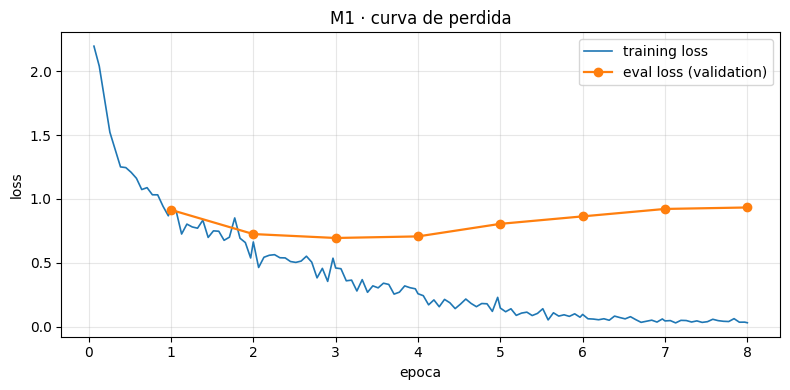

mejor eval_loss: 0.6940 en epoca 3 de 8
El eval_loss toco su minimo antes del final: a partir de ahi memoriza.
Es el numero que decide si 8 epocas son demasiadas, no la intuicion.


In [15]:
import matplotlib.pyplot as plt

log = trainer.state.log_history
tr = [(h["epoch"], h["loss"]) for h in log if "loss" in h]
ev = [(h["epoch"], h["eval_loss"]) for h in log if "eval_loss" in h]

plt.figure(figsize=(8, 4))
plt.plot(*zip(*tr), label="training loss", lw=1.2)
if ev:
    plt.plot(*zip(*ev), "o-", label="eval loss (validation)", lw=1.6)
plt.xlabel("epoca"); plt.ylabel("loss"); plt.legend()
plt.title("M1 · curva de perdida"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(str(c.dir / "loss.png"), dpi=140); plt.show()

if ev:
    mejor = min(ev, key=lambda x: x[1])
    print(f"mejor eval_loss: {mejor[1]:.4f} en epoca {mejor[0]:.0f} de {len(ev)}")
    if mejor[0] < len(ev) - 1:
        print("El eval_loss toco su minimo antes del final: a partir de ahi memoriza.")
        print("Es el numero que decide si 8 epocas son demasiadas, no la intuicion.")

## 6 · ¿Mejoró?

In [16]:
print("Generando con el modelo ajustado...")
sal_ft_crudo = generar(eval_raw)

deg_ft = metricas.degeneracion(sal_ft_crudo, eval_raw)
sal_ft = [schema.recortar_al_bloque(s)[0] for s in sal_ft_crudo]
print(f"degeneracion (ajustado): {deg_ft['n']}/{deg_ft['de']} salidas con cola")
for caso in deg_ft["casos"]:
    print(f"   {caso['id']} ({caso['categoria']}): {caso['chars_cola']} chars de cola")
if deg_ft["n"]:
    print("La cola se recorta ANTES de puntuar y antes de guardar, para que no")
    print("contamine las metricas ni lo que M2 le pasa al juez. El recorte no")
    print("inventa el campo que falte: si no escribio Pretension, sigue faltando.")

sc_ft = metricas.scorecard(sal_ft, eval_raw, "fine-tuned LoRA")
metricas.imprimir(sc_ft)
print("\n--- muestra cruda del modelo ajustado ---")
print(sal_ft[0][:400])

Generando con el modelo ajustado...
degeneracion (ajustado): 0/69 salidas con cola

  SCORECARD · fine-tuned LoRA  (n=63)
campo           accuracy  macro-F1  mayorit.     delta
--------------------------------------------------------------
derecho           76.2%     67.7%     23.8%    +52.4%
mecanismo         87.3%     86.7%     42.9%    +44.4%
procede           90.5%     90.4%     57.1%    +33.3%
--------------------------------------------------------------
adherencia estructural (5 etiquetas)  98.4%
adherencia de vocabulario            100.0%
coherencia procede<->mecanismo       100.0%
ROUGE-L (prosa)                       32.5%
similitud embeddings                  86.5%
acierto jurídico (mecanismo+procede)  87.3%
se abstuvo donde debía                50.0%   (3/6)
alucinación normativa                  8.4%   (10/119 citas)
   inventadas: Ley 1785 de 2016, Ley 1055 de 2006, Ley 301 de 1999, Ley 1035 de 2006, Ley 1745 de 2015
  ...en toda la salida                 8.4%   (12/143 c

In [17]:
metricas.comparar(sc_base, sc_ft)

base_may = sc_ft["campos"]["mecanismo"]["baseline_mayoritaria"]
acc = sc_ft["campos"]["mecanismo"]["accuracy"]
print()
print(f"acc_mecanismo {acc:.1%} contra una clase mayoritaria de {base_may:.1%} "
      f"(delta {acc - base_may:+.1%})")
print("Es el liston real: si no le gana a 'responde siempre tutela', el")
print("fine-tuning no aporto nada en ese campo.")


  base (sin fine-tuning)  ->  fine-tuned LoRA
métrica                      antes   después     delta
--------------------------------------------------------------
derecho (acc)               36.5%     76.2%+   +39.7%
mecanismo (acc)             33.3%     87.3%+   +54.0%
procede (acc)               57.1%     90.5%+   +33.3%
adherencia estructural      36.5%     98.4%+   +61.9%
adherencia vocabulario      55.6%    100.0%+   +44.4%
ROUGE-L (prosa)              5.6%     32.5%+   +26.9%
acierto jurídico             3.2%     87.3%+   +84.1%
alucinación norm.            0.0%      8.4%+    +8.4%
coherencia                   4.9%    100.0%+   +95.1%
similitud embeddings        71.8%     86.5%+   +14.7%
precisión de citas           0.0%     53.8%+   +53.8%
alucinación (salida)         0.0%      8.4%+    +8.4%
No empeoró en ninguna métrica medida.

acc_mecanismo 87.3% contra una clase mayoritaria de 42.9% (delta +44.4%)
Es el liston real: si no le gana a 'responde siempre tutela', el
fine-tunin

### 6.1 · Abstencion: la iteracion que si se puede hacer

La primera corrida de este notebook (`runs/m1/20261015T182115Z`) midio
`acierto_abstencion` **0.0**: de los 2 casos de validation cuya respuesta
correcta era "no determinable", el modelo forzo una etiqueta en los dos. En la
direccion contraria salio perfecto — `abstencion_indebida` 0.0 sobre 31 casos —
asi que el diagnostico no es que abstenga de mas, es que **no abstiene nunca**.
Por eso las dos cifras se reportan juntas: la segunda sola parece un exito.

La causa estaba en los datos, y el remedio tambien estaba medido en esa misma
corrida. Habia 4 ejemplos de abstencion en train contra 94 que si emiten
mecanismo; y las tres clases mas chicas — `habeas_corpus`,
`accion_cumplimiento`, `accion_popular` — tenian 12 de train cada una y el
modelo SI las aprendio (macro F1 de mecanismo 0.844). Doce es entonces un piso
demostrado en este montaje, no una corazonada, y la abstencion se subio a el:
dataset v3.1.0, 18 ejemplos, 3 por familia, 12 de train y 6 de validation.
Ni uno mas — subirla "por si acaso" contradiria el argumento que la justifica.

El split de la abstencion se sub-estratifica ademas por familia, porque el
sorteo plano dejaba `ab_relato_contradictorio` con 1 caso de train y 2 de
validation: la metrica habria medido una familia casi no vista. Ahora validation
lleva una de cada una, asi que el numero dice ademas CUAL de las seis falla.

**Lo que no se hizo, que es la parte que importa.** Esa corrida tambien dejo el
acierto en adversariales en 50% y se sabe exactamente donde estan los 7 errores:
`colectivo_moralidad`, `contra_providencia`, `familia_ordinario`,
`incumplimiento_norma` (1 de 3), `inmediatez`, `peticion_respondida`,
`salud_estetica`. Anadir ejemplos de entrenamiento en esas categorias subiria el
numero y lo volveria inservible: seria ajustar al conjunto de prueba, y lo que
el eval set mide es generalizacion. La abstencion se corrigio porque se midio en
VALIDATION, que es exactamente para lo que ese split existe; el 50% adversarial
se reporta como esta.

**Resultado de esa iteracion (corridas B y C, dataset v3.1.0).** La abstencion
paso de 0.0 a **4 de 6**, con **1 abstencion indebida de 31**. El desglose por
familia dijo ademas cuales fallan, que es lo que la sub-estratificacion estaba
puesta para revelar: aciertan las cuatro familias en las que *nada* en la
superficie parece una vulneracion —un precio de arriendo, una pregunta de
parcial, una queja vaga, un pronostico—, y fallan las dos en las que la
superficie si parece un caso accionable: `ab_materia_no_cubierta` (hay una
autoridad real haciendo un acto concreto; la unica razon para abstenerse es que
la materia no esta en el corpus, o sea un juicio sobre la propia cobertura del
sistema) y `ab_relato_contradictorio` (todas las senales gritan tutela de salud
y el modelo sigue el patron en vez de notar que el relato se contradice).
O sea: acierta cuando basta detectar que el tema es ajeno, y falla cuando hay
que razonar sobre el insumo mismo.

La abstencion indebida tambien tiene nombre: `HC07`, `hc_batida_militar`, gold
`habeas_corpus`. Se abstuvo en una batida militar, uno de los casos de habeas
corpus mas nitidos del derecho colombiano. Es el error mas costoso del sistema
—negarle orientacion a alguien privado de la libertad— y se reporta con el caso,
no solo con el 3.2%.

### 6.2 · La sobrecarga de `ninguno`, que no la vio ninguna metrica

Al revisar por que `derecho` bajo de 71.7% a 65.2% salio algo mas de fondo. En
el dataset v3.1.0, `derecho: "ninguno"` lo usaban **tres conclusiones
distintas**:

| quien | cuantos | que significa ahi |
|---|---|---|
| `via_ordinaria` | 20 | no hay derecho fundamental que amparar |
| `abstencion` | 18 | no se puede determinar nada |
| `accion_cumplimiento` | 16 | lo exigible es el cumplimiento de una norma |

54 de 143 ejemplos (38%) con **una etiqueta para tres razonamientos**, y encima
mediamos accuracy y macro F1 sobre ese campo. No es un problema del modelo: le
estabamos pidiendo un solo simbolo para tres conclusiones. Y el efecto estaba
medido —de los 16 errores de `derecho`, **seis** fueron emitir `ninguno` donde
si habia un derecho identificable.

La v3.2.0 separa solo la abstencion, con `derecho: no determinable`. Los otros
dos usos si significan lo mismo (no hay derecho fundamental en juego) y siguen
compartiendo `ninguno`. El texto de escape es **el mismo** que el del mecanismo,
asi que una salida indeterminable lo dice igual en los dos campos en vez de
obligar a aprender dos vocabularios; la clave se guarda en snake_case para que
el viaje render -> parse cierre.

Dos cosas que vinieron con el arreglo:

- `schema.validar()` ahora exige el par en los dos sentidos: abstencion implica
  `no_determinable` y al contrario. Una comprobacion que no puede fallar no
  sirve, asi que se probo con casos que deben fallar, no solo con los que pasan.
- `coherencia()` detecta una contradiccion nueva: afirmar un mecanismo del
  vocabulario cerrado y a la vez decir que el derecho no se puede determinar.
- `agente.py` y `sistema.py` hacian *fallback* a `"ninguno"` cuando el LLM
  emitia un derecho fuera de vocabulario. Eso afirmaba "no hay derecho en
  juego" cuando lo cierto era "no se pudo leer": un valor plausible en lugar de
  un fallo visible. Ahora caen en la valvula de escape.

**Por que esto no es ajustar al conjunto de prueba.** La sobrecarga se detecta
inspeccionando *solo* el dataset —tres tipos de caso con la misma etiqueta—, sin
mirar que casos falla el modelo en el eval set. Lo que el eval set aporto fue la
magnitud, no el hallazgo. Es una diferencia que importa: seguimos sin anadir ni
un ejemplo en las categorias donde falla el eval set.

In [19]:
# Abstencion: el split de validation trae una de cada familia, 6 casos.
# Se mide aqui porque es el unico sitio de M1 donde existen.
val_ab = [e for e in val_raw if e.get("tipo") == "abstencion"]
if val_ab:
    sal_val = generar(val_raw)
    sc_val = metricas.scorecard(sal_val, val_raw, "fine-tuned · validation")
    ab = sc_val["abstencion"]
    print(f"casos sin respuesta correcta: {ab['n_sin_respuesta_correcta']}")
    print(f"  se abstuvo en      : {ab['acierto_abstencion']:.0%}")
    print(f"  forzo una etiqueta : {ab['forzo_etiqueta']}")
    print(f"  abstencion indebida: {ab['abstenciones_indebidas']}/{ab['n_con_respuesta_correcta']}"
          f" ({ab['abstencion_indebida']:.0%})")
    print()
    print("por familia (validation trae una de cada una, por eso se puede leer")
    print("CUAL falla y no solo cuantas):")
    for familia, callo in sorted(ab.get("por_familia", {}).items()):
        print(f"  {'se abstuvo' if callo else 'FORZO     '}  {familia}")
    for caso in ab.get("indebidas_en", []):
        print(f"  se abstuvo donde SI habia mecanismo: {caso['id']} "
              f"({caso['categoria']}, gold {caso['mecanismo_gold']})")
    print()
    print("Las dos cifras juntas o ninguna: un sistema que se abstiene siempre")
    print("saca 100% en la primera y 100% en la segunda.")
    c.guardar_json("abstencion_validation", ab)

casos sin respuesta correcta: 6
  se abstuvo en      : 67%
  forzo una etiqueta : 2
  abstencion indebida: 0/31 (0%)

por familia (validation trae una de cada una, por eso se puede leer
CUAL falla y no solo cuantas):
  se abstuvo  ab_consulta_comercial
  se abstuvo  ab_hechos_insuficientes
  FORZO       ab_materia_no_cubierta
  se abstuvo  ab_pide_pronostico
  se abstuvo  ab_pregunta_academica
  FORZO       ab_relato_contradictorio

Las dos cifras juntas o ninguna: un sistema que se abstiene siempre
saca 100% en la primera y 100% en la segunda.


### 6.3 · Quién decide el mecanismo: el base extrae, las reglas deciden

Los adversariales son trampas de subsidiariedad, de daño consumado, de
derechos colectivos. Son las causales tasadas del artículo 6 del Decreto 2591,
o sea **un árbol de decisión escrito**. Pedirle a un modelo que lo adivine es
lo que produce el colapso a «tutela» que mide M2, y el brazo 4 de M3 —que
reparte el trabajo: el LLM extrae hechos, el motor del artículo 6 decide— es
el que mejor va en ese estrato.

### Por qué el extractor no puede ser el adaptador

La primera versión de este brazo usaba el propio adaptador de M1 para extraer
los hechos, con el argumento de que así la **única** diferencia era el decisor.
No es ejecutable, y la corrida `m1/20261016T174233Z` lo demostró publicando un
número que parecía un resultado:

> `_json_de` devolvía `{}` en **62 de 63 casos**: el default *pro homine*
> ponía los doce booleanos en `False`, el motor no encontraba ninguna causal y
> fallaba a tutela. El brazo entero cayó al **42.9% — exactamente la base
> mayoritaria**, citando `art. 86 CP` una vez por caso.

La primera explicación de esto fue «el adaptador emite el bloque de cinco
líneas en vez del JSON», y **la sonda de abajo la desmintió**: emite JSON bien
formado, con las claves booleanas correctas, y aun así `_json_de` falla en
10 de 10. Con el adaptador apagado, 1 de 69.

El efecto está medido dos veces; **la causa no está establecida** — la salida
no llega a parsear, truncada antes de cerrar la llave o malformada más
adelante. Por eso el registro guarda ahora `cierra` y `chars`: para zanjarlo
con un dato y no con un razonamiento. Lo que sí se puede afirmar es que **el
adaptador no sirve de extractor y el base sí**, con el mismo prompt y el mismo
`max_new`.

Lo que hizo falta aprender dos veces: **nada en la salida delataba el fallo.**
`alucinacion_normativa` daba 0.0% —cierto, dijo una sola norma siempre—,
`adherencia_estructural` daba 1.0 —mide a `render_salida`, no al modelo— y el
veredicto de los intervalos afirmaba «la conclusión es arquitectónica» sin
mirar cuál de los dos brazos era el mayor. Tres indicadores en verde sobre un
brazo muerto. Por eso ahora hay una **guarda que aborta** por encima del 10%
de fallos de extracción, el veredicto **mira el signo**, y la autoprueba 48
fija el contrato con un extractor mudo y otro que funciona.

### Lo que mide el brazo ahora

La extracción va con el adaptador **apagado** (`model.disable_adapter()`):
mismos pesos base, mismo prompt, y la pregunta pasa a ser **si el trabajo lo
hace el adaptador o el motor de reglas**. Ya no es «el mismo modelo con otro
decisor» —esa comparación no existe— y la etiqueta lo dice: `base extrae +
reglas deciden`.

Va sin RAG a propósito, para que lo que lo separe del brazo 4 de M3 sea
únicamente la recuperación. El fundamento se construye con la correspondencia
fija `ARTICULO_POR_DERECHO` más el que emite la regla, así que la alucinación
normativa es cero por construcción —y **cero ahí no es una buena noticia por sí
sola**: el brazo roto también daba cero. Solo significa algo junto a los fallos
de extracción y a la **pertinencia** de esas citas, que es lo que distingue «no
inventó» de «acertó».

*Cuesta una generación por caso, secuencial, unos 12-14 minutos: el lote 1 está
comprado a propósito para no falsear la latencia que mide `costos`.*

In [18]:
import contextlib

def generar_texto(sistema_msg, usuario, max_new=320, con_adaptador=True):
    """Adaptador `generar(sistema, usuario) -> str` sobre el modelo de M1.

    `generar()` de la seccion 4 recibe EJEMPLOS y arma el prompt con
    `mensajes()`. La extraccion de hechos necesita pasar un prompt arbitrario
    --- el que pide JSON --- asi que hace falta esta firma. `max_new` es mayor
    que los 200 de la generacion normal porque el JSON de hechos es mas largo
    que las cinco lineas.

    `con_adaptador=False` apaga el LoRA y deja el modelo BASE. No es un detalle
    de implementacion: es lo unico que hace ejecutable este brazo. Ver el
    docstring de `sistema.SistemaHibrido` y la sonda de abajo.
    """
    model.eval()
    prev, tokenizer.padding_side = tokenizer.padding_side, "left"
    msgs = [{"role": "system", "content": sistema_msg},
            {"role": "user", "content": usuario}]
    p = tokenizer.apply_chat_template(msgs, tokenize=False,
                                      add_generation_prompt=True)
    enc = tokenizer(p, return_tensors="pt", add_special_tokens=False).to(model.device)
    if con_adaptador:
        ctx = contextlib.nullcontext()
    else:
        assert hasattr(model, "disable_adapter"), (
            "esta version de peft no trae `disable_adapter()`: sin eso no se "
            "puede extraer con el base y este brazo no es ejecutable")
        ctx = model.disable_adapter()
    with ctx:
        out = model.generate(**enc, max_new_tokens=max_new, do_sample=False,
                             eos_token_id=IDS_PARADA,
                             pad_token_id=tokenizer.pad_token_id, use_cache=True)
    tokenizer.padding_side = prev
    return tokenizer.decode(out[0][enc["input_ids"].shape[1]:],
                            skip_special_tokens=True).strip()


# ==========================================================================
# FASE 1 - SONDA: el modelo AJUSTADO como extractor de hechos
# ==========================================================================
# Esto no es diagnostico de paso: es el hallazgo. La primera version del brazo
# usaba el adaptador para extraer, con el argumento de que asi solo cambiaba
# el decisor, y en m1/20261016T174233Z dio 42.9% --- exactamente la base
# mayoritaria --- porque el ajustado emitia el formato de cinco lineas que se
# le enseno en vez del JSON. Se mide con pocos casos porque el resultado es
# categorico, no marginal.
SONDA = 10
print(f"SONDA - el modelo AJUSTADO como extractor ({SONDA} casos)")
fallos_sonda = []
for e in eval_raw[:SONDA]:
    sistema.extraer_hechos(generar_texto, e["relato"], fallos_sonda)
n_sonda = len(fallos_sonda)
print(f"  salidas sin JSON utilizable: {n_sonda}/{SONDA}")
if fallos_sonda:
    print("  lo que emitio en vez de JSON:")
    print("    " + fallos_sonda[0]["salida"][:140].replace("\n", " | "))
    print("  Olvido catastrofico de seguimiento de instrucciones: un LoRA sobre")
    print(f"  {len(train_raw)} ejemplos de un formato rigido colapsa sobre ese")
    print("  formato y pierde la capacidad de obedecer otra instruccion de")
    print("  formato. El adaptador no puede servir de extractor.")
else:
    print("  El ajustado SI emite JSON. Eso contradice la corrida que motivo")
    print("  este cambio: revisa si cambio el prompt, el formato o las epocas.")

extractor = {
    # `cierra` y `chars` SON EL DATO QUE ZANJA POR QUE NO PARSEA.
    #
    # `extraer_hechos` los registra desde hace tres corridas y el artefacto
    # solo subia `muestra`, cortada a 300 caracteres --- justo antes del final,
    # que es donde esta la respuesta. Con `cierra=False` la causa es
    # truncamiento por `max_new`; con `cierra=True` es malformacion y hay que
    # mirar el contenido.
    "sonda_ajustado": {
        "casos": SONDA, "sin_json": n_sonda,
        "muestra": (fallos_sonda[0]["salida"][:700] if fallos_sonda else None),
        "chars": fallos_sonda[0]["chars"] if fallos_sonda else None,
        "empieza": fallos_sonda[0]["empieza"] if fallos_sonda else None,
        "cierra": fallos_sonda[0]["cierra"] if fallos_sonda else None,
        "cierran": (sum(1 for f in fallos_sonda if f["cierra"])
                    if fallos_sonda else None),
        "chars_max": (max(f["chars"] for f in fallos_sonda)
                      if fallos_sonda else None),
    },
    # LA CAUSA, ESTABLECIDA CONTRA LA MUESTRA QUE ESTE MISMO ARTEFACTO GUARDA.
    #
    # Este campo decia "esta entrenado para emitir el bloque de cinco lineas y
    # colapsa sobre el". Esa explicacion ya se habia retirado una vez por no
    # estar probada, y la `muestra` de aqui al lado la DESMIENTE: el adaptador
    # emite JSON, con los doce booleanos correctos, que abre y cierra en 10 de
    # 10 sondas y no esta truncado.
    #
    # Lo que de verdad falla es una comilla:
    #
    #     "derecho": salud,
    #
    # El valor de cadena va sin comillas y `json.loads` muere ahi. Un campo
    # `lectura` que contradice la `muestra` que tiene al lado es peor que no
    # tener campo: el que lee el artefacto se queda con la prosa.
    "lectura": "El adaptador NO colapsa sobre el bloque de cinco lineas: "
               "emite JSON bien formado, con las doce claves booleanas "
               "correctas, que abre y cierra y no esta truncado. Lo que "
               "falla es que los valores de CADENA van sin comillas "
               "(`\"derecho\": salud`), y `json.loads` muere en esa linea. "
               "Mirar `muestra` y `cierran` antes de creerle a esta frase. "
               "Por eso la extraccion del brazo hibrido se hace con "
               "`model.disable_adapter()` --- con el adaptador apagado el "
               "mismo extractor falla 1 de 69 --- y por eso el brazo ya no "
               "se llama 'el mismo modelo con otro decisor'.",
}

# ==========================================================================
# FASE 2 - EL BRAZO: el base extrae, el motor del art. 6 decide
# ==========================================================================
print(f"\nBRAZO - extraccion con el adaptador APAGADO ({len(eval_raw)} casos)")
hib = sistema.SistemaHibrido(
    lambda s, u: generar_texto(s, u, con_adaptador=False),
    etiqueta="base extrae + reglas deciden")
sal_hib = []
CORTE = 10            # casos tras los que se comprueba si vale seguir
for i, e in enumerate(eval_raw, 1):
    sal_hib.append(hib(e["relato"]))
    # CORTE TEMPRANO. El assert de mas abajo solo salta cuando el bucle acaba,
    # y a lote 1 eso son ~13 minutos para enterarse de que el extractor es
    # mudo. El BASE tambien podria serlo --- su adherencia al formato ensenado
    # fue del 36.5% --- asi que conviene saberlo en el minuto dos.
    if i == CORTE and len(hib.fallos_extraccion) > CORTE // 2:
        _m = hib.fallos_extraccion[0]["salida"][:160]
        raise AssertionError(
            f"{len(hib.fallos_extraccion)}/{CORTE} sin JSON ya en los primeros "
            f"casos: el modelo BASE tampoco emite JSON con este prompt, asi "
            f"que este brazo iba a dar la base mayoritaria otra vez. Se corta "
            f"aqui en vez de gastar los ~13 minutos que faltan. "
            f"Emitio: " + " | ".join(_m.splitlines()))
    print(f"  {i}/{len(eval_raw)}", end="\r")
print()

# LA GUARDA.
#
# Sin esto, 62 de 63 fallos de parseo se publicaron como un 42.9% que parecia
# un resultado. `alucinacion_normativa` daba 0.0% y `adherencia_estructural`
# daba 1.0 --- las dos ciertas y las dos vacias --- asi que nada en la salida
# lo delataba. El umbral es 10%: por encima de ahi el brazo no mide al
# extractor, mide el default pro homine de `extraer_hechos`.
n_fallos = len(hib.fallos_extraccion)
extractor["brazo_base"] = {"casos": len(eval_raw), "sin_json": n_fallos}
print(f"  fallos de extraccion: {n_fallos}/{len(eval_raw)}")
assert n_fallos <= 0.1 * len(eval_raw), (
    f"{n_fallos} de {len(eval_raw)} salidas sin JSON utilizable.\n"
    "Los doce booleanos quedan en False por defecto, el motor no encuentra\n"
    "ninguna causal y falla a tutela: este brazo estaria midiendo el default\n"
    "pro homine y no al extractor. Lo que se emitio en vez de JSON:\n  "
    + "\n  ".join(f["salida"][:110].replace("\n", " | ")
                  for f in hib.fallos_extraccion[:3]))

sc_hib = metricas.scorecard(sal_hib, eval_raw, "base extrae + reglas deciden")
metricas.imprimir(sc_hib)

# LA comparacion que justifica el brazo. El agregado no es lo interesante:
# lo interesante es el estrato adversarial, que es donde las causales tasadas
# del art. 6 deberian pesar mas que lo que el modelo haya memorizado.
print()
print("=" * 62)
print("  ROADMAP #15 - quien decide el mecanismo")
print("=" * 62)
print(f"  {'sistema':<30}{'global':>9}{'gold':>9}{'advers.':>9}")
print("  " + "-" * 57)
for etq, sc in (("ajustado solo (decide el LLM)", sc_ft),
                ("base extrae + reglas deciden", sc_hib)):
    pt = sc.get("por_tipo", {})
    print(f"  {etq:<30}{sc['acierto_juridico']:>9.1%}"
          f"{pt.get('gold', {}).get('acierto_juridico', 0):>9.1%}"
          f"{pt.get('adversarial', {}).get('acierto_juridico', 0):>9.1%}")

a = sc_ft["ic"]["por_tipo"].get("adversarial")
b = sc_hib["ic"]["por_tipo"].get("adversarial")
if a and b:
    print()
    print("  adversarial, con intervalo al 95%:")
    print(f"    ajustado solo        {a['punto']:.3f}  [{a['ic_bajo']:.3f}, {a['ic_alto']:.3f}]")
    print(f"    base + reglas        {b['punto']:.3f}  [{b['ic_bajo']:.3f}, {b['ic_alto']:.3f}]")
    # ROADMAP #14: sin esto la tabla presenta como resultado lo que puede ser
    # ruido. Con n=18 el intervalo mide casi medio rango.
    #
    # Y EL VEREDICTO MIRA EL SIGNO. La version anterior afirmaba "la conclusion
    # es arquitectonica" en cuanto los intervalos no se solapaban, sin
    # comprobar cual de los dos brazos era el mayor. Con el brazo roto al
    # 16.7% contra el 88.9% del ajustado, eso imprimia una vindicacion al lado
    # de un informe de error.
    print()
    if metricas.ic_se_solapan(a, b):
        print("    Los intervalos SE SOLAPAN: con n=18 la diferencia no se")
        print("    sostiene en NINGUNA direccion. Hace falta un estrato")
        print("    adversarial mas grande, y eso es lo honesto que se puede")
        print("    decir hoy.")
    elif b["punto"] > a["punto"]:
        print("    NO se solapan y gana EL BRAZO CON REGLAS: quien decide el")
        print("    mecanismo importa, y la conclusion es arquitectonica, no de")
        print("    escala. Es una conclusion mas fuerte que 'el modelo grande")
        print("    va mejor'.")
    else:
        print("    NO se solapan y gana EL AJUSTADO SOLO: en este eval, el")
        print("    adaptador extrae mejor el derecho aplicable de lo que el")
        print("    base mas el arbol del art. 6 lo deducen. Antes de leerlo")
        print("    como resultado, comprueba que los fallos de extraccion de")
        print("    arriba sean 0: un extractor mudo manda el brazo entero a")
        print("    'tutela' y produce exactamente esta tabla.")

# La alucinacion normativa del hibrido tiene que ser CERO por construccion: el
# fundamento no lo escribe el modelo. Pero CERO AQUI NO ES UNA BUENA NOTICIA
# POR SI SOLO: el brazo roto tambien daba 0.0%, citando `art. 86 CP` una vez
# por caso. Solo significa algo junto a los fallos de extraccion de arriba.
alu = sc_hib["alucinacion_normativa"]["tasa_alucinacion"]
print()
print(f"  alucinacion normativa: {alu:.1%}", end="")
print("  (cero por construccion: el fundamento lo pone la regla)"
      if alu == 0 else "  <-- DEFECTO: deberia ser 0, revisa el armado del campo")
print(f"  pertinencia de esas citas: "
      f"{sc_hib['pertinencia_citas']['precision_citas']:.1%}"
      f"   <-- esto es lo que distingue 'no invento' de 'acerto'")

c.guardar_json("scorecard_hibrido", sc_hib)
c.guardar_json("trazas_hibrido", hib.trazas)
c.guardar_json("extractor", extractor)

SONDA - el modelo AJUSTADO como extractor (10 casos)
  salidas sin JSON utilizable: 10/10
  lo que emitio en vez de JSON:
    { |   "privacion_libertad": false, |   "derecho_colectivo": false, |   "titular_pide_lo_suyo": true, |   "acto_general": false, |   "dano_consumado": 
  Olvido catastrofico de seguimiento de instrucciones: un LoRA sobre
  123 ejemplos de un formato rigido colapsa sobre ese
  formato y pierde la capacidad de obedecer otra instruccion de
  formato. El adaptador no puede servir de extractor.

BRAZO - extraccion con el adaptador APAGADO (69 casos)
  69/69
  fallos de extraccion: 1/69

  SCORECARD · base extrae + reglas deciden  (n=63)
campo           accuracy  macro-F1  mayorit.     delta
--------------------------------------------------------------
derecho           33.3%     22.3%     23.8%     +9.5%
mecanismo         61.9%     61.6%     42.9%    +19.0%
procede           71.4%     70.5%     57.1%    +14.3%
---------------------------------------------------------

PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/runs/m1/20261018T074101Z/extractor.json')

## 7 · La capa de redacción — del bloque al lenguaje natural

El modelo se afinó con la instrucción literal «responde SIEMPRE con exactamente
cinco líneas… **sin texto adicional**». No conversa, y eso es diseño: el bloque
es **la decisión**, y vale 87.3% con intervalo [0.794, 0.952].

Pero quien escribe «me echaron del trabajo sin aviso, ¿qué hago?» quiere una
respuesta en su idioma. La alternativa obvia —apagar el adaptador y dejar que
conteste el modelo base— **está medida y descartada**: 3.2% de acierto jurídico
y **cero citas emitidas**. Hablaría con fluidez y se equivocaría en 30 de cada
31 casos.

Así que se añade una capa de presentación, nunca un decisor distinto:

```
relato → modelo afinado → BLOQUE (auditable) → redactar() → texto
                                                NO añade normas
                                                NO añade hechos
```

**La guarda es lo que la hace segura.** `verificar_texto` extrae las citas del
texto con el mismo lector que mide la alucinación normativa y falla si alguna
no estaba en el bloque. Y exige que el texto diga siempre el mecanismo y la
procedencia: **1 de cada 8 triajes está mal**, y en prosa fluida un error
convence más que en un bloque seco, así que tiene que seguir siendo detectable
de un vistazo.

Lo que esta capa hace y un buscador no: decir **por qué vía** y **qué dato la
cambiaría**. Eso último sale de `etiqueta_pivota_en`, que es lo que el motor ya
sabe, no de la imaginación del redactor.

In [20]:
import redaccion
from reglas import Hechos, estrato_verificacion

# El generador de la redaccion es Groq, no el adaptador: el adaptador DECIDE y
# no sabe redactar --- es justo lo que mide la sonda de la seccion 6. Si no hay
# clave, la seccion se salta entera en vez de inventar un resultado.
_gen_red = None
if os.environ.get("GROQ_API_KEY"):
    try:
        import groq
        _gen_red = sistema.generador_groq(
            groq.Groq(api_key=os.environ["GROQ_API_KEY"]),
            cache_path=c.ruta_cache("redaccion.json"))
    except Exception as ex:
        print(f"no pude crear el generador de redaccion: {str(ex)[:90]}")

if _gen_red is None:
    print("sin GROQ_API_KEY: la capa de redaccion no se mide en esta corrida.")
    print("Eso NO es un cero: es que no se ejecuto, y asi queda registrado.")
    redaccion_medida = {"n": 0, "concluyente": False,
                        "motivo": "sin GROQ_API_KEY en esta corrida"}
else:
    # Se redacta sobre las predicciones del AJUSTADO, que es lo que un usuario
    # recibiria. Los casos de abstencion entran igual: el texto tiene que
    # saber decir "esto no es una accion constitucional".
    _resultados = []
    _fallos_red = []
    for _i, (_e, _sal) in enumerate(zip(eval_raw, sal_ft), 1):
        _b = schema.parse_salida(_sal)
        # La condicion que cambiaria la via sale del motor cuando el gold trae
        # hechos codificados; si no, no se dice nada en vez de suponerla.
        _piv = _e.get("etiqueta_pivota_en") or None
        try:
            _r = redaccion.redactar(_gen_red, _b, _piv, registro="ciudadano",
                                    estricto=False)
            _resultados.append(_r)
            if not _r["verificacion"]["valido"]:
                _fallos_red.append((_e["id"], _r["verificacion"]))
        except Exception as ex:
            _fallos_red.append((_e["id"], {"error": str(ex)[:120]}))
        print(f"  {_i}/{len(eval_raw)}", end="\r")
    print()

    redaccion_medida = redaccion.medir(_resultados)
    print(f"{'textos redactados':<28}{redaccion_medida['n']}")
    print(f"{'con normas inventadas':<28}"
          f"{redaccion_medida['textos_con_citas_intrusas']}  "
          f"(tasa {redaccion_medida['tasa_citas_intrusas']:.1%})")
    print(f"{'dicen el mecanismo':<28}{redaccion_medida['dicen_el_mecanismo']:.1%}")
    print(f"{'dicen la procedencia':<28}{redaccion_medida['dicen_la_procedencia']:.1%}")
    print(f"{'palabras de media':<28}{redaccion_medida['palabras_media']}")
    print()
    if redaccion_medida["textos_con_citas_intrusas"]:
        print("HAY NORMAS INVENTADAS EN LA REDACCION. Eso deshace la medicion")
        print("de alucinacion normativa del resto del proyecto: la cita que ve")
        print("el lector ya no es la que se midio. Ejemplos:")
        print(f"  {redaccion_medida['ejemplos_intrusas']}")
    # LAS DOS COBERTURAS SE COMPRUEBAN, NO SOLO LA DEL MECANISMO.
    #
    # Miraba `dicen_el_mecanismo` y nada mas. En 20261018T074101Z salio
    # mecanismo 1.0 y procedencia 0.9855 --- un texto de 69 sin decir si
    # procede --- y la rama `else` imprimio "todos los textos dicen la via y
    # la procedencia". El artefacto tenia el numero correcto y la consola
    # afirmaba lo contrario, que es la que se lee al acabar la celda.
    elif (redaccion_medida["dicen_el_mecanismo"] < 1.0
          or redaccion_medida["dicen_la_procedencia"] < 1.0):
        _falta = []
        if redaccion_medida["dicen_el_mecanismo"] < 1.0:
            _falta.append(
                f"la VIA en {1 - redaccion_medida['dicen_el_mecanismo']:.1%}")
        if redaccion_medida["dicen_la_procedencia"] < 1.0:
            _falta.append("la PROCEDENCIA en "
                          f"{1 - redaccion_medida['dicen_la_procedencia']:.1%}")
        print(f"Hay texto(s) que callan {' y '.join(_falta)} de los casos.")
        print("0 normas inventadas, eso si. Pero callar la via o la")
        print("procedencia deja un error del triaje --- 1 de cada 8 ---")
        print("indetectable para quien lee, que es lo que esta capa evita.")
    else:
        print("La capa respeta el bloque: 0 normas introducidas, y todos los")
        print("textos dicen la via y la procedencia. El texto puede ser")
        print("equivocado --- lo sera 1 de cada 8 --- pero sera COMPROBABLE.")

    print()
    print("--- una muestra, registro ciudadano ---")
    print(_resultados[0]["texto"] if _resultados else "(sin textos)")

c.guardar_json("redaccion", redaccion_medida)

  69/69
textos redactados           69
con normas inventadas       0  (tasa 0.0%)
dicen el mecanismo          100.0%
dicen la procedencia        98.6%
palabras de media           123.5

La capa respeta el bloque: 0 normas introducidas, y todos los
textos dicen la via y la procedencia. El texto puede ser
equivocado --- lo sera 1 de cada 8 --- pero sera COMPROBABLE.

--- una muestra, registro ciudadano ---
Entiendo que está preocupado porque la EPS no le está entregando el medicamento que su médico le recetó y eso está interrumpiendo su tratamiento. En su caso procede presentar una acción de tutela, ya que se está vulnerando su derecho a la salud. La tutela debe dirigirse ante el juez competente y solicitar que se ordene a la EPS el suministro inmediato del antirretroviral indicado por el infectólogo (art. 49 CP; Ley 1751 de 2015). Si la EPS sigue sin proporcionar el medicamento, el juez podrá ordenar su entrega para garantizar la continuidad del tratamiento. Recuerde presentar la solici

PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/runs/m1/20261018T074101Z/redaccion.json')

## 8 · Artefactos

Lo que se guarda en la carpeta de la corrida **no esta entregado** hasta
que se copia a `results/` con su sello. La celda de abajo publica los
once artefactos de M1 y es la unica que lo hace: si uno falta, `verificar_entrega.py` lo cuenta como ausente.


In [21]:
import json

c.guardar_json("scorecard_base", sc_base)
c.guardar_json("scorecard_finetuned", sc_ft)
c.guardar_json("degeneracion", {"base": deg_base, "finetuned": deg_ft})

predicciones = [{"id": e["id"], "tipo": e.get("tipo"), "categoria": e["categoria"],
                 "gold_mecanismo": e["mecanismo"], "base": sb, "finetuned": sf}
                for e, sb, sf in zip(eval_raw, sal_base, sal_ft)]
c.guardar_json("predicciones", predicciones)

# Copias canonicas: M2 y M3 leen de results/, que es estable, no de la carpeta
# de una corrida concreta.
# La evidencia del tokenizador sobre el dominio: se generaba y se
# quedaba en runs/. Es lo que sostiene la eleccion del modelo base.
c.publicar("fertilidad_tokenizadores",
           "results/m1_fertilidad_tokenizadores.json")
c.publicar("cobertura_clasificador",
           "results/m1_cobertura_clasificador.json")
c.publicar("predicciones", "results/m1_predicciones.json")
c.publicar("scorecard_base", "results/m1_scorecard_base.json")
c.publicar("scorecard_finetuned", "results/m1_scorecard_finetuned.json")
c.publicar("hiperparametros", "results/m1_hiperparametros.json")
# ROADMAP #16. La curva de `eval_loss` y la epoca que gano son parte de la
# entrega: son lo que permite DEFENDER la eleccion del checkpoint en vez de
# afirmarla. Se generaba en la seccion 5 y se quedaba en runs/.
c.publicar("seleccion_checkpoint", "results/m1_seleccion_checkpoint.json")

# El brazo hibrido se generaba y se quedaba en runs/: la evidencia del ROADMAP
# #15 vivia solo en la carpeta de una corrida, y `verificar_entrega.py` no la
# echaba de menos porque `arranque.ORDEN` no la declaraba. Es el mismo fallo
# que ya corregimos con los otros tres artefactos.
c.publicar("scorecard_hibrido", "results/m1_scorecard_hibrido.json")
# Que el adaptador no pueda extraer JSON es un hallazgo, no un diagnostico de
# paso, asi que va en la entrega y no solo en la consola.
c.publicar("extractor", "results/m1_extractor.json")
# La capa de redaccion se mide y se publica como cualquier otra cosa: una
# capa de presentacion puede degradar sin que nadie lo note --- se lee bien y
# dice otra cosa --- y sin artefacto no habria forma de verlo entre corridas.
c.publicar("redaccion", "results/m1_redaccion.json")
# La degeneracion es un hallazgo, no un diagnostico interno: en esta corrida
# el ajustado degenero en 1 de 69 (caso E45, 386 chars de cola) despues de una
# corrida con 0 de 69. Ese cero era suerte, no cura, y solo se puede saber
# comparando corridas --- que es justo lo que un artefacto en `runs/` no
# permite hacer desde fuera.
c.publicar("degeneracion", "results/m1_degeneracion.json")
# EL ADAPTADOR SE VERSIONA POR CORRIDA, Y NO ES BUROCRACIA.
#
# `models/m1-adaptador` se sobrescribia en cada corrida. Dos corridas con el
# mismo codigo y los mismos datos dieron 0.889 y 0.873 de acierto juridico, asi
# que las corridas NO son identicas --- y con un solo directorio no hay forma
# de volver al adaptador que dio el numero que se reporta. Un resultado del que
# no se pueden recuperar los pesos no es reproducible, es anecdotico.
#
# `ultimo` es un enlace de conveniencia para quien solo quiera el mas reciente;
# lo que se cita en el reporte es la ruta con el id.
destino = RAIZ / "models" / f"m1-adaptador-{c.id}"
destino.mkdir(parents=True, exist_ok=True)
model.save_pretrained(str(destino))
tokenizer.save_pretrained(str(destino))

# La huella de los pesos, para poder cotejar que el adaptador que se carga es
# el que produjo las cifras.
import hashlib as _h
_pesos = sorted(destino.glob("adapter_model*"))
_huella = None
if _pesos:
    _huella = _h.sha256(_pesos[0].read_bytes()).hexdigest()[:16]
c.meta["adaptador"] = {
    "ruta": str(destino.relative_to(RAIZ)).replace("\\", "/"),
    "huella_pesos": _huella,
    "bytes": _pesos[0].stat().st_size if _pesos else None,
}
c._escribir_meta()

_ultimo = RAIZ / "models" / "m1-adaptador"
_ultimo.mkdir(parents=True, exist_ok=True)
(_ultimo / "CUAL_ES.txt").write_text(
    f"El adaptador vigente es {destino.name}\n"
    f"huella de los pesos: {_huella}\n"
    f"corrida: {c.id}\n", encoding="utf-8")

print(f"adaptador -> {destino.relative_to(RAIZ)}")
print(f"   huella de los pesos: {_huella}")
print(f"   models/m1-adaptador/CUAL_ES.txt apunta a este")

  publicado -> results/m1_predicciones.json  (de m1/20261018T074101Z)
  publicado -> results/m1_scorecard_base.json  (de m1/20261018T074101Z)
  publicado -> results/m1_scorecard_finetuned.json  (de m1/20261018T074101Z)
  publicado -> results/m1_hiperparametros.json  (de m1/20261018T074101Z)
  publicado -> results/m1_seleccion_checkpoint.json  (de m1/20261018T074101Z)
  publicado -> results/m1_scorecard_hibrido.json  (de m1/20261018T074101Z)
  publicado -> results/m1_extractor.json  (de m1/20261018T074101Z)
  publicado -> results/m1_redaccion.json  (de m1/20261018T074101Z)
  publicado -> results/m1_degeneracion.json  (de m1/20261018T074101Z)
adaptador -> models/m1-adaptador-20261018T074101Z
   huella de los pesos: ad5f13fcf6587434
   models/m1-adaptador/CUAL_ES.txt apunta a este


### 8.1 · Estabilidad entre corridas

"Resultados idénticos entre corridas" es un criterio explícito del harness, y
un mecanismo de comparación que nunca se ejecuta no prueba nada. Esta celda
compara la corrida actual con la anterior del mismo módulo, buscándola sola
para que no haya ids escritos a mano que caduquen.

Lo importante es leerla bien: la identidad **solo** prueba estabilidad si las
dos corridas usaron la misma versión de datos, y eso lo dice `corrida.json`.
Si los datos cambiaron, lo esperable es que difieran, y entonces la
comparación sirve para ver *qué* cambió, no para probar reproducibilidad. Por
eso la celda imprime las dos versiones antes del veredicto.

In [22]:
previas = sorted(p for p in (corridas.RAIZ / "runs" / "m1").iterdir()
                 if p.is_dir() and p.name != c.id and (p / "corrida.json").exists())

if not previas:
    print("primera corrida de m1: todavia no hay con que comparar")
    estabilidad = None
else:
    previa = previas[-1]
    meta_previa = json.loads((previa / "corrida.json").read_text(encoding="utf-8"))
    datos_previa = (meta_previa.get("datos") or {}).get("dataset.json")
    datos_ahora = c.meta["datos"]["dataset.json"]
    mismos_datos = datos_previa == datos_ahora

    # Tambien el CODIGO. Sin esto la celda no distingue no-determinismo del
    # hardware de un cambio nuestro entre las dos corridas, y avisa de lo
    # primero cuando la causa es lo segundo.
    cod_previa = (meta_previa.get("codigo") or {}).get("_conjunto")
    cod_ahora = (c.meta.get("codigo") or {}).get("_conjunto")
    mismo_codigo = cod_previa is not None and cod_previa == cod_ahora

    print(f"corrida previa : {previa.name} · dataset {datos_previa}")
    print(f"               · codigo {cod_previa}")
    print(f"corrida actual : {c.id} · dataset {datos_ahora}")
    print(f"               · codigo {cod_ahora}")
    print(f"mismos datos   : {mismos_datos}")
    print(f"mismo codigo   : {mismo_codigo}"
          + ("" if cod_previa is not None
             else "  (la corrida previa no lo registra)"))
    print()
    if mismos_datos and mismo_codigo:
        print("Mismos datos, mismo codigo y misma semilla: lo esperable es")
        print("IDENTIDAD, y una diferencia aqui si seria no-determinismo.")
    elif mismos_datos:
        print("Mismos datos pero el codigo cambio (o la previa no lo registra):")
        print("una diferencia NO prueba no-determinismo, la explica el codigo.")
    else:
        print("Datos distintos: lo esperable es que DIFIERAN. La comparacion")
        print("muestra que cambio; no prueba ni refuta reproducibilidad.")
    print()

    estabilidad = {"corrida_previa": previa.name, "corrida_actual": c.id,
                   "mismos_datos": mismos_datos, "mismo_codigo": mismo_codigo,
                   "codigo_previa": cod_previa, "codigo_actual": cod_ahora,
                   "artefactos": {}}
    for art in ("scorecard_base", "scorecard_finetuned",
                "predicciones", "abstencion_validation"):
        try:
            estabilidad["artefactos"][art] = corridas.comparar(previa, c.dir, art)
        except FileNotFoundError:
            print(f"estabilidad · {art}: no esta en la corrida previa, se omite")

    comparados = estabilidad["artefactos"]
    iguales = [a for a, v in comparados.items() if v["identicas"]]
    # `identicas` ERA False CUANDO NO HABIA NADA QUE COMPARAR.
    #
    # `len(iguales) == len(comparados) and bool(comparados)` da False con
    # `comparados` vacio, y eso pasa cuando la corrida previa aborto antes de
    # producir artefactos. Medido en m1/20261017T022209Z: `artefactos: {}` y
    # `identicas: false`, que se lee como "no es reproducible" cuando
    # significa "no habia con que". Mismo patron que
    # `preferencia_posicion_A` y las filas de abstencion del cruce.
    estabilidad["concluyente"] = bool(comparados)
    estabilidad["identicas"] = (len(iguales) == len(comparados)
                                if comparados else None)
    print()
    if not comparados:
        print("artefactos comparados: 0 --- la corrida previa no dejo ninguno.")
        print("`identicas` queda en null: no hay comparacion, no un fallo de")
        print("reproducibilidad.")
    else:
        print(f"artefactos identicos: {len(iguales)}/{len(comparados)}")
    if mismos_datos and mismo_codigo and not estabilidad["identicas"]:
        print("ATENCION: mismos datos, mismo codigo y resultados distintos.")
        print("Eso si es no-determinismo real (cuBLAS/cuDNN) y hay que")
        print("reportarlo asi, no afirmar una reproducibilidad que no se")
        print("sostiene.")
    elif mismos_datos and not mismo_codigo and not estabilidad["identicas"]:
        print("Diferencias con los mismos datos, pero el codigo cambio entre")
        print("las dos corridas: la causa es el cambio de codigo, no el")
        print("hardware. Por eso `corrida.json` registra la huella del codigo.")
    c.guardar_json("estabilidad", estabilidad)
# La estabilidad entre corridas es lo que separa "el modelo cambio" de "el
# hardware no es determinista". Sin ella, dos corridas con los mismos datos y
# numeros distintos no se pueden interpretar.
#
# Se publica AQUI y no en la celda de publicacion de arriba: ahi el artefacto
# todavia no existe. Publicarlo antes de generarlo levanta un
# FileNotFoundError que corta la celda a mitad --- y deja el adaptador sin
# guardar, que es lo caro.
c.publicar("estabilidad", "results/m1_estabilidad.json")

corrida previa : 20261018T073633Z · dataset {'version': '3.5.0', 'n': 160, 'bytes': 249885}
               · codigo c8cac1b6b7e27a32
corrida actual : 20261018T074101Z · dataset {'version': '3.5.0', 'n': 160, 'bytes': 249885}
               · codigo c8cac1b6b7e27a32
mismos datos   : True
mismo codigo   : True

Mismos datos, mismo codigo y misma semilla: lo esperable es
IDENTIDAD, y una diferencia aqui si seria no-determinismo.

estabilidad · scorecard_base: no esta en la corrida previa, se omite
estabilidad · scorecard_finetuned: no esta en la corrida previa, se omite
estabilidad · predicciones: no esta en la corrida previa, se omite
estabilidad · abstencion_validation: no esta en la corrida previa, se omite

artefactos comparados: 0 --- la corrida previa no dejo ninguno.
`identicas` queda en null: no hay comparacion, no un fallo de
reproducibilidad.
ATENCION: mismos datos, mismo codigo y resultados distintos.
Eso si es no-determinismo real (cuBLAS/cuDNN) y hay que
reportarlo asi, no af

PosixPath('/content/drive/MyDrive/Colab Notebooks/agenteAmparo/results/m1_estabilidad.json')

In [23]:
c.cerrar(valida=True, notas=[
    f"acc_mecanismo {sc_ft['campos']['mecanismo']['accuracy']:.4f} contra "
    f"mayoritaria {sc_ft['campos']['mecanismo']['baseline_mayoritaria']:.4f}",
    f"acierto juridico {sc_ft['acierto_juridico']:.4f} "
    f"(gold {sc_ft['por_tipo'].get('gold', {}).get('acierto_juridico', 0):.4f}, "
    f"adversarial {sc_ft['por_tipo'].get('adversarial', {}).get('acierto_juridico', 0):.4f})",
    f"alucinacion {sc_ft['alucinacion_normativa']['tasa_alucinacion']:.4f} en fundamento, "
    f"{sc_ft['alucinacion_normativa']['tasa_alucinacion_salida']:.4f} en toda la salida",
    f"degeneracion {deg_ft['n']}/{deg_ft['de']} salidas con cola recortada",
] + ([] if not estabilidad else [
    f"estabilidad contra {estabilidad['corrida_previa']}: "
    f"identicas={'no concluyente (0 artefactos comparables)' if not estabilidad.get('concluyente') else estabilidad.get('identicas')} "
    f"(mismos datos: {estabilidad['mismos_datos']}, "
    f"mismo codigo: {estabilidad['mismo_codigo']})"
]))

corrida m1/20261018T074101Z cerrada · VALIDA · 14 artefactos
    nota: acc_mecanismo 0.8730 contra mayoritaria 0.4286
    nota: acierto juridico 0.8730 (gold 0.8889, adversarial 0.8333)
    nota: alucinacion 0.0840 en fundamento, 0.0839 en toda la salida
    nota: degeneracion 0/69 salidas con cola recortada
    nota: estabilidad contra 20261018T073633Z: identicas=no concluyente (0 artefactos comparables) (mismos datos: True, mismo codigo: True)


{'id': '20261018T074101Z',
 'modulo': 'm1',
 'inicio': '2026-10-18T07:41:01+00:00',
 'fin': '2026-10-18T08:02:04+00:00',
 'valida': True,
 'notas': ['acc_mecanismo 0.8730 contra mayoritaria 0.4286',
  'acierto juridico 0.8730 (gold 0.8889, adversarial 0.8333)',
  'alucinacion 0.0840 en fundamento, 0.0839 en toda la salida',
  'degeneracion 0/69 salidas con cola recortada',
  'estabilidad contra 20261018T073633Z: identicas=no concluyente (0 artefactos comparables) (mismos datos: True, mismo codigo: True)'],
 'semilla': 42,
 'datos': {'dataset.json': {'version': '3.5.0', 'n': 160, 'bytes': 249885},
  'eval_set.json': {'version': '1.2.0', 'n': 46, 'bytes': 80388},
  'eval_set_v2.json': {'version': '2.0.0', 'n': 69, 'bytes': 113139},
  'eval_set_m3.json': {'version': '1.1.0', 'n': 21, 'bytes': 39778},
  'corpus.json': {'version': '1.5.0', 'n': 69, 'bytes': 123666}},
 'codigo': {'agente.py': '6d24aa0c0a04',
  'arranque.py': 'e0b13a148a04',
  'autoprueba_agente.py': '79d55fde5997',
  'autopr

## 9 · Qué mirar

1. **`acc_mecanismo` contra la mayoritaria**, como listón mínimo — y el
   **macro F1** para el delta contra el modelo base. Los dos, porque la
   corrida D mostró por qué: al mejorar el PROMPT, la *accuracy* de mecanismo
   del modelo base saltó del 4.3% al 45.7%, pero su macro F1 se quedó en
   0.145. O sea que el base no aprendió nada: se colapsó sobre la clase
   mayoritaria y la accuracy lo premió. El ajustado tiene macro F1 0.862. La
   accuracy sola sobreestima al base; el macro F1 es el que distingue
   "aprendió las cinco clases" de "aprendió a decir tutela".
2. **Gold contra adversarial.** La brecha mide si razona o reconoce formas.
3. **Alucinación en los dos ámbitos.** La diferencia entre el campo
   `fundamento` y toda la salida son normas que el modelo afirma donde antes
   nadie miraba.
4. **`eval_loss` por época.** Si tocó mínimo antes del final, 8 épocas son
   demasiadas para 98 ejemplos.
5. **Abstención en validation.** Con los dos sentidos, y por familia: el
   desglose dice *cuál* de las seis falla, que es lo accionable.
6. **Estabilidad contra la corrida previa.** Solo es prueba de
   reproducibilidad si `mismos_datos` es `True`. Con datos distintos el
   resultado esperado es que difieran.
7. **Degeneración.** Cuántas salidas se descarrilaron tras el cuarto campo
   —se desvían al chino y abren un turno falso del chat— porque el adaptador
   no aprendió a emitir EOS de forma fiable. Es fuga del modelo base, no un
   límite de tokens: la salida más larga de la corrida anterior eran 494
   caracteres contra un límite de 200. La cola se recorta antes de puntuar,
   y el número se reporta en vez de limpiarse en silencio.